### The spectrum, snow and modes of `im_dino_w21_wd`

The KAE stands in for DINOv3 ViT-B/16's blocks 7 to 12. It encodes the state after block 6, applies K once, and decodes a prediction of the state after block 12. DINOv3's final layer norm and an ImageNet linear probe then read the predicted CLS token as if it were the real block 12. The probe plays the part CLIP's zero-shot classifier plays in the CLIP notebooks.

A state is the CLS token, the mean of the 196 patch tokens and their spread (std), so 2,304 numbers per block. Only the CLS part goes through the probe.

`im_dino_w21_wd`: Jordan K (1 real mode and 1,024 two-by-two blocks), TopK 256 (128 modes per image), shared modes, a 2-layer encoder and decoder 4,096 wide, weight decay 0.1, trained for 12 epochs on 3 views of ImageNet plus 1.16 million ImageNet-21k images.

Each two-by-two block is one mode with one complex eigenvalue `λ`. Its size `|λ|` is how much the mode grows from block 6 to block 12, and its angle is how far the mode's two numbers turn. We edit a mode by multiplying `λ`: by a real number to change its size, or by `e^(iθ)` to turn it by `θ`. Nothing else changes.

NOTE: DINOv3 is loaded with `transformers`, which has to be importable from the notebook's kernel.

##### What we found

Everything is measured on ImageNet's 50,000 validation images unless a line says otherwise.

**Accuracy.** The KAE reaches 61.8% probe accuracy and gives DINOv3's answer on 66.5% of images. DINOv3 itself reaches 83.9%. Almost all of the 22-point gap opens at K: block 12 pushed through the encoder and decoder alone scores 81.0%, and 79.5% when it has to use the modes picked at block 6. K's prediction scores 61.8%. Giving every mode its true angle at block 12 (keeping K's size) lifts that to 74.2%, and giving it its true size (keeping K's angle) to 73.1%. These are ceilings, as they use block 12 itself.

**The spectrum.** 457 of the 1,025 modes are ever kept. They fall into four groups:
- 2 **growth** modes (331 and 77), on for every image, with `|λ|` of 18.9 and 14.4 and angles of 10° and 8°. They hold 78% of the latent energy at block 12. Removing either costs 7 to 10 points.
- 10 **offset** modes, on for every image with nearly the same value, so they carry the average state. They turn by 14° to 174° (median 82°) and hold 63% of the latent energy at block 6. The large angles are used: setting mode 338's angle to 0 at the same size costs 7.6 points.
- 4 **inert** modes that sit at `|λ|` ≈ 1 and do nothing.
- 441 **feature** modes, on for some images only. 305 of them have `|λ|` between 5 and 10 and turn by 5° to 45°. The other 136 have `|λ|` under 5 and hardly turn.

Unlike the CLIP runs, nearly every kept mode grows.

**The modes every image keeps.** 16 of each image's 128 modes are the same 16 for every image.
- The 10 offset modes carry the average state, and their large angles come from the shared standardization. With one mean and std for both blocks, the average block-6 state and the average block-12 state are opposite (cosine -1.00) and equally long, while block-12 states are spread 10.7 times wider around their average than block-6 states. So K has to flip the average at the same length and grow the rest about tenfold. The offset modes do the first job: they are among the slowest-growing kept modes (`|λ|` of 0.6 to 3.5, against a median of 7.6 for feature modes) and hold 9 of the 10 largest angles in the spectrum. Mode 861 is close to a multiplication by -1.2. Giving them the same value for every image costs 0.5 points. Setting their angles to 0 costs 9.7 points, more than removing them (5.1).
- The 2 growth modes are the two fastest-growing modes, with ordinary turns (10° and 8°, under the feature median of 12°). Each is a point on a plane that every image has, and the direction it points in says what type of image it is. For mode 331, going round the plane: small objects on plain backgrounds, a single subject against an empty field (a shark, a fruit), close-ups that fill the frame (pets, food), reefs, animals in vegetation, outdoor machines and gatherings, street vehicles, office furniture and electronics. The direction matters more than the size: giving every image mode 331's average size costs 1.3 points, giving it the average direction costs 8.8.
- The 4 inert modes do nothing: no edit of them changes any answer.

**Do modes follow their eigenvalue?** On average, yes: the measured gain tracks `|λ|` (correlation 0.97) and the measured turn is within 1° of the angle of `λ` for half the modes. Image by image, only partly: `λ·z₆` explains 58% of the variation of `z₁₂` for the median feature mode, and 16% for the modes that turn by under 5°. That unexplained part is where the 18 points at K go.

**Snow.** DINOv3 is not fooled by snow: 86.0% on the 129 snowy photos against 82.9% on normal images of the same classes. The KAE is: 34.1% against 67.7%, answering snowplow (35 images) and snowmobile (22). So here snow is a failure of the KAE, not of the model it stands in for.
- Snow is spread over several modes. The top ones fire on winter woods (667), on snow and white water (644), on open water (37) and, at the top of its range, on piles of fruit and balls (247).
- Removing the top 4 takes snowy accuracy to 57.4% (31 images fixed, 1 broken) and leaves the normal vehicles unchanged. Picking the modes on one half of the test and scoring the other gives 56% and 58%. It stays far below DINOv3's 86%.
- The cost: of the 25,815 validation images that keep one of the 4 modes, removal fixes 312 and breaks 574.
- Turning against removing: for mode 667 alone, a turn of +90° fixes 15 snowy images where removal fixes 6. With 4 or more modes, removal and a 180° turn tie near 58%, and the turns break more validation images.
- K is not wrong about the snow modes. Giving them their true block-12 value changes little (38.8%), while giving every other mode its true value recovers 69.8%. On snowy vehicles the snow modes really do grow by about `|λ|`, as they do on snowplows. So removing them deletes evidence that is truly there, to make up for the vehicle evidence K fails to produce. It is a patch, not a repair.

**DINOv3's own mistakes.** DINOv3 is wrong on 8,032 validation images. For 80% of them the label is among its top 5 answers, and the most common mix-ups are look-alike or overlapping labels: tights and one-piece bathing suit, laptop and notebook computer, collie and Shetland Sheepdog. The KAE inherits them: on these images it is right 12.9% of the time, against 71.1% on the rest.
- Some modes flag these images beyond what their classes explain: 28 modes have a score above 3.7 where chance gives none, and the scores repeat across two halves of the images (correlation 0.67).
- Editing the flagged modes does not fix the mistakes. Removing one breaks at least about as many answers as it fixes, through K and on the true block 12, and turns break more. Picking the modes to remove on one half of the images and scoring the other half gives no gain.
- So on ImageNet itself the modes can say where DINOv3 is likely wrong, and cannot repair it. The weak spots the DINOv3 paper reports for this model lie outside ImageNet's photos: drawings and other renditions (76.7% on ImageNet-R) and ObjectNet (64.1%).

**Modes.** 95% of the modes kept on at least 0.5% of images have top images more alike than chance, and most group images across classes: round fruit and balls, shaggy dogs, birds against the sky, antelope herds, knitted fabric. Modes drawn at random look much the same. Removing a mode nearly always hurts: summed over modes, removal fixes 51,909 answers and breaks 97,332. The modes that matter most are dog modes.

**Size against turn.** Over 40 feature modes, turning a mode by 45° moves DINOv3's feature in a direction that is mostly new (cosine -0.36 with the move made by scaling), while a turn of 180° acts like scaling down (-0.93). So a turn reaches outputs that a change of size cannot, but on this model no turn improves accuracy on the images that keep the mode.

**Limits.** The snow test has 129 images, so one image is 0.8 points. The snow modes and the best turns are picked on the images they are scored on, except in the two held-out checks. Passing the coherence bar means "more alike than chance", not "interpretable". The model was still improving when training stopped at 12 epochs.

In [1]:
import math
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
from datasets import load_dataset
from dotenv import load_dotenv
from PIL import Image
from safetensors.torch import load_file
from sklearn.metrics import roc_auc_score
from torchvision import transforms

sys.path.insert(0, "../scripts/tokae")
import train

load_dotenv("../.env")
torch.set_grad_enabled(False)
torch.manual_seed(0)
torch.set_num_threads(32)
pd.set_option("display.width", 220)

NAME, ENCODER = "im_dino_w21_wd", "dinov3-vitb16"
CKPT_DIR = Path(os.getenv("WEIGHTS_CACHE")) / "tokae"
# From wandb, for this checkpoint. The prediction cell must reproduce them, or loading is wrong.
EXPECTED = {"probe accuracy": 0.61778, "agrees with DINOv3": 0.66488}
NUM_SNOW_MODES = 6
NUM_COHERENT = 10
NUM_RANDOM = 6
SNOW_FOLDERS = {
    "armytank": 847,
    "carwheel": 479,
    "firetruck": 555,
    "motorscooter": 670,
    "racingcar": 751,
    "schoolbus": 779,
    "trafficlight": 920,
}

BLUE, ORANGE, MUTED, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)

/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


##### Model and data

States are standardized with the statistics the model was trained with. With shared modes, block 12 keeps the modes TopK picked at block 6, so every kept mode has a value at both ends. We write each mode's two numbers as one complex number: `z₆` at block 6 and `z₁₂` at block 12. K then says `z₁₂ ≈ λ·z₆`, mode by mode.

NOTE: No gallery in this notebook shows insects, arachnids or their relatives (crabs, lobsters and crayfish included). Images of those classes are skipped, along with worms, snails, slugs, chitons, starfish, sea urchins, honeycombs, apiaries, spider webs and any image for which one of those classes is among DINOv3's top 5 answers. Modes that mostly fire on such images are left out of the galleries. They still count in every number.

In [2]:
root = Path(os.getenv("DATASETS_CACHE"))
stats = torch.load(CKPT_DIR / f"{NAME}_stats.pt")
mean, std = stats["mean"], stats["std"]

# shape: [images, 2, 2304], the state after blocks 6 and 12
val = torch.load(root / "imagenet" / f"clip_cls_patch_std_{ENCODER}_val_blocks_5_11.pt")
val_x, val_y = (val["states"].float() - mean) / std, val["labels"]
images = load_dataset("ILSVRC/imagenet-1k", split="validation", cache_dir=os.getenv("DATASETS_CACHE"))
assert torch.equal(val_y, torch.tensor(list(images["label"]))), "cached labels don't follow the image order"
class_names = open_clip.IMAGENET_CLASSNAMES

kae = train.JordanKoopmanAutoencoder(
    top_k=256,
    shared_modes=stats["shared_modes"],
    in_features=val_x.shape[-1],
    latent_features=2049,
    hidden_config=stats["hidden_config"],
    bias=True,
    batchnorm=False,
    nonlinearity="leaky_relu",
)
kae.load_state_dict(load_file(CKPT_DIR / f"{NAME}.safetensors"))
kae.eval()

# DINOv3's final layer norm and the ImageNet linear probe, as used in training
head = train.DinoHead(ENCODER, mean, std, torch.device("cpu"), zero_shot=True)

# Images we never show: insects, arachnids and their relatives (crabs, lobsters and crayfish too), worms, snails, slugs and chitons,
# starfish and sea urchins (leggy or spiny), honeycombs and apiaries (bees) and spider webs,
# by label or by any of DINOv3's top 5 answers, as images of other classes can contain them too
HIDDEN_CLASSES = torch.tensor([*range(69, 80), 110, 111, *range(113, 117), *range(118, 127), *range(300, 329), 410, 599, 815])
hidden = torch.isin(val_y, HIDDEN_CLASSES) | torch.isin(head.get_log_probs(val_x[:, 1]).topk(5).indices, HIDDEN_CLASSES).any(dim=1)
# NOTE: Hidden by hand, as the class filter cannot see it: a menu with a drawing of a crayfish
HIDDEN_IMAGES = [22037]
hidden[HIDDEN_IMAGES] = True

# shape: [modes]. Mode 0 is the real eigenvalue, mode m > 0 is the block on latent coordinates 2m - 1 and 2m
eigenvalues = torch.cat([kae.real_eigenvalue.to(torch.cfloat), torch.complex(kae.block_real, kae.block_imag)])
size, angle = eigenvalues.abs(), torch.rad2deg(torch.angle(eigenvalues))


def to_complex(phi):
    """Each mode as one complex number (mode 0 is real)."""

    return torch.cat([phi[..., :1].to(torch.cfloat), torch.view_as_complex(phi[..., 1:].unflatten(-1, (-1, 2)).contiguous())], dim=-1)


def to_latent(z):
    return torch.cat([z[..., :1].real, torch.view_as_real(z[..., 1:]).flatten(-2)], dim=-1)


def decode(z):
    return torch.cat([kae.decode(to_latent(batch)) for batch in z.split(5_000)])


def edit(z_start, changes):
    """
    The KAE's prediction of block 12 with some eigenvalues multiplied by a factor. `changes` maps mode to factor.
    NOTE: The encoder doesn't depend on K, so we encode once and only redo K and the decoder.
    """

    edited = eigenvalues.clone()
    for mode, factor in changes.items():
        edited[mode] = edited[mode] * factor
    return decode(edited * z_start)


def turn(degrees):
    return complex(math.cos(math.radians(degrees)), math.sin(math.radians(degrees)))


# shape: [images, modes], complex, at blocks 6 and 12
z = to_complex(torch.cat([train.encode_pairs(kae, batch) for batch in val_x.split(2_500)]))
z6, z12 = z[:, 0], z[:, 1]
assert torch.allclose(to_complex(kae.koopman_forward(to_latent(z6[:100]), 1)), eigenvalues * z6[:100], atol=1e-4), "K is not λ·z₆ mode by mode"

kept = z6 != 0
usage = kept.double().mean(dim=0)
print(f"{NAME}: hidden {stats['hidden_config']}, shared modes {stats['shared_modes']}, standardization {stats['standardization']}, {int(kept.sum(dim=1).median())} modes kept per image")

/home/dunstan/git/koopmann/koopmann/models/autoencoder.py:48: UserWarning: The latent dimension 2049 should probably be larger than the input dimension 2304!
  warnings.warn(


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

im_dino_w21_wd: hidden [4096, 4096], shared modes True, standardization global, 128 modes kept per image


##### Prediction

Probe accuracy on ImageNet's 50,000 validation images, and how often the KAE gives the same answer as DINOv3, right or wrong. These must match the numbers wandb logged for this checkpoint.

In [3]:
true_answers = head.classify(val_x[:, 1])
answers = head.classify(decode(eigenvalues * z6))
scores = {
    "probe accuracy": (answers == val_y).double().mean().item(),
    "agrees with DINOv3": (answers == true_answers).double().mean().item(),
}
for key, value in scores.items():
    assert abs(value - EXPECTED[key]) < 0.002, f"{key}: {value:.4f} here, {EXPECTED[key]} on wandb"

pd.DataFrame(
    {
        "DINOv3": {"probe accuracy": (true_answers == val_y).double().mean().item(), "agrees with DINOv3": 1.0},
        "KAE": scores,
    }
).T.round(3)

,probe accuracy,agrees with DINOv3
DINOv3,0.839,1.000
KAE,0.618,0.665


##### The spectrum

One eigenvalue per mode. Each block also has the conjugate `a - ib`, so the sign of an angle is a convention and we plot its size only. On the left, the complex plane, folded onto its upper half. On the right, the same modes as angle against size, with size on a log scale.

We sort modes into five groups, by rules on the validation images:
- **never kept**: TopK never picks the mode.
- **growth**: on for at least 99% of images, with a value that differs from image to image.
- **offset**: on for at least 99% of images with nearly the same value for all of them (the average value is over twice the spread), so it carries the average state, not something about the image.
- **inert**: an offset mode holding under 0.1% of the latent energy at block 6.
- **feature**: everything else, on for some images and off for others.

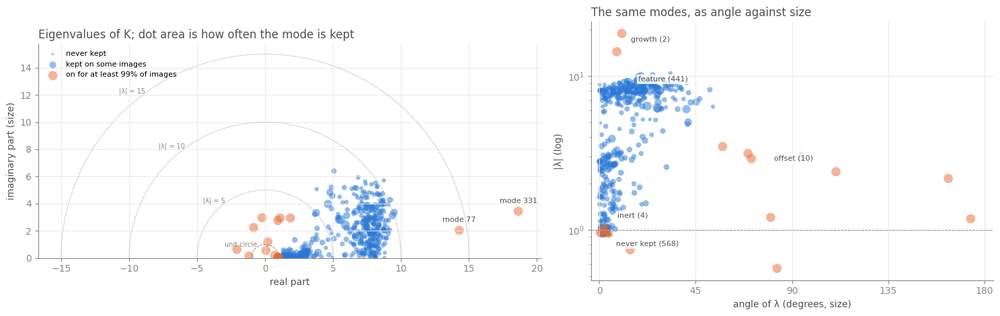

457 of 1025 modes are ever kept, 16 are on for at least 99% of images
Kept modes, |λ| at the 5th, 25th, 50th, 75th and 95th percentile: [1.16, 2.94, 7.52, 8.33, 9.44]
Kept modes, angle (size) at the same percentiles: [1.0, 4.5, 12.4, 21.6, 37.4]


,modes,median_size,median_angle,median_kept,block_6_energy,block_12_energy
group,,,,,,
growth,2,16.686001,9.304,0.997,0.163,0.780
offset,10,2.275000,81.527,1.000,0.631,0.057
inert,4,0.961000,2.149,0.998,0.002,0.000
feature,441,7.623000,12.079,0.213,0.204,0.164
never kept,568,0.985000,1.685,0.000,0.000,0.000


In [4]:
energy6, energy12 = z6.abs().pow(2).sum(dim=0), z12.abs().pow(2).sum(dim=0)
share6, share12 = energy6 / energy6.sum(), energy12 / energy12.sum()

# How steady a mode's block-6 value is over images: the size of its average, over its spread around it
mean6 = z6.mean(dim=0)
steadiness = mean6.abs() / (z6 - mean6).abs().pow(2).mean(dim=0).sqrt().clamp_min(1e-12)
never, always = usage == 0, usage >= 0.99
steady = always & (steadiness > 2)
group = np.select(
    [never.numpy(), (always & ~steady).numpy(), (steady & (share6 < 1e-3)).numpy(), steady.numpy()],
    ["never kept", "growth", "inert", "offset"],
    "feature",
)

spectrum = pd.DataFrame(
    {
        "group": group,
        "|λ|": size.numpy(),
        "|angle|": angle.abs().numpy(),
        "kept": usage.numpy(),
        "share of block-6 latent energy": share6.numpy(),
        "share of block-12 latent energy": share12.numpy(),
    }
)
summary = spectrum.groupby("group").agg(
    modes=("kept", "size"),
    median_size=("|λ|", "median"),
    median_angle=("|angle|", "median"),
    median_kept=("kept", "median"),
    block_6_energy=("share of block-6 latent energy", "sum"),
    block_12_energy=("share of block-12 latent energy", "sum"),
)
summary = summary.loc[[g for g in ["growth", "offset", "inert", "feature", "never kept"] if g in summary.index]]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
styles = [("never kept", MUTED, never), ("kept on some images", BLUE, ~never & ~always), ("on for at least 99% of images", ORANGE, always)]

ax = axes[0]
for radius in [1, 5, 10, 15]:
    arc = radius * np.exp(1j * np.linspace(0, np.pi, 200))
    ax.plot(arc.real, arc.imag, color=MUTED, lw=0.7, ls="--" if radius == 1 else ":")
    ax.annotate("unit circle" if radius == 1 else f"|λ| = {radius}", (radius * math.cos(2.2), radius * math.sin(2.2)), fontsize=7, color=MUTED, ha="right")
for label, color, mask in styles:
    ax.scatter(eigenvalues.real[mask].numpy(), eigenvalues.imag[mask].abs().numpy(), s=8 + 90 * usage[mask].numpy(), color=color, alpha=0.5, lw=0, label=label)
for mode in np.flatnonzero(group == "growth"):
    ax.annotate(f"mode {mode}", (eigenvalues.real[mode].item(), abs(eigenvalues.imag[mode].item())), xytext=(0, 9), textcoords="offset points", fontsize=8, color=INK, ha="center")
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part (size)")
ax.set_aspect("equal")
ax.set_ylim(0, None)
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Eigenvalues of K; dot area is how often the mode is kept", loc="left", color=INK)

ax = axes[1]
for label, color, mask in styles:
    ax.scatter(angle[mask].abs().numpy(), size[mask].numpy(), s=8 + 90 * usage[mask].numpy(), color=color, alpha=0.5, lw=0)
ax.axhline(1.0, color=MUTED, lw=0.7, ls="--")
ax.set_yscale("log")
ax.set_xlim(-4, 184)
ax.set_xticks([0, 45, 90, 135, 180])
ax.set_xlabel("angle of λ (degrees, size)")
ax.set_ylabel("|λ| (log)")
offsets = {"growth": (12, 0), "offset": (0, 16), "feature": (14, 14), "inert": (14, 16), "never kept": (14, -16)}
for name, row in summary.iterrows():
    ax.annotate(
        f"{name} ({int(row['modes'])})",
        (row["median_angle"], row["median_size"]),
        xytext=offsets[name],
        textcoords="offset points",
        fontsize=8,
        color=INK,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
    )
ax.set_title("The same modes, as angle against size", loc="left", color=INK)
fig.tight_layout()
plt.show()

used = ~never
quantiles = torch.tensor([0.05, 0.25, 0.5, 0.75, 0.95])
print(f"{int(used.sum())} of {len(usage)} modes are ever kept, {int(always.sum())} are on for at least 99% of images")
print("Kept modes, |λ| at the 5th, 25th, 50th, 75th and 95th percentile:", [round(q, 2) for q in size[used].quantile(quantiles).tolist()])
print("Kept modes, angle (size) at the same percentiles:", [round(q, 1) for q in angle[used].abs().quantile(quantiles).tolist()])
summary.round(3)

##### Does a mode do what its eigenvalue says?

`λ` is one number shared by every image, so a mode behaves as `λ` says only if `z₁₂ ≈ λ·z₆` image by image. For each mode kept on at least 0.5% of images, over the images that keep it:
- **measured gain**: the median of `|z₁₂| / |z₆|`, against `|λ|`.
- **measured turn**: the angle of `Σ z₁₂·conj(z₆)`, which is the one turn that best fits all the images, against the angle of `λ`.
- **turn agreement**: `|Σ z₁₂·conj(z₆)| / Σ |z₁₂||z₆|`. It is 1 if every image turns by the same angle, and near 0 if the images turn every which way.
- **R²**: how much of the image-to-image variation of `z₁₂` is explained by `λ·z₆`.

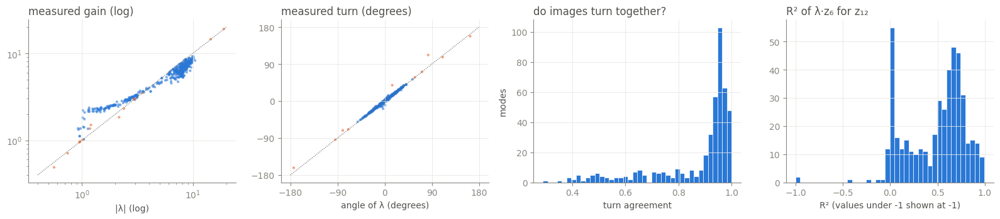

455 modes kept on at least 0.5% of images. Orange: growth, offset and inert modes; blue: feature modes.
Gain against |λ|: correlation 0.973 (of logs). Turn against angle: median gap 0.7°, 90th percentile 2.7°


turn agreement           R²       
                 count median count median
group                                     
feature            439  0.941   439  0.576
growth               2  0.998     2  0.992
inert                4  1.000     4 -0.016
offset              10  0.995    10  0.381

In [5]:
rows = []
for mode in (usage >= 0.005).nonzero()[:, 0].tolist():
    on = kept[:, mode]
    a, b = z6[on, mode], z12[on, mode]
    pooled = (b * a.conj()).sum()
    rows.append(
        {
            "mode": mode,
            "group": group[mode],
            "|λ|": size[mode].item(),
            "angle": angle[mode].item(),
            "kept": usage[mode].item(),
            "measured gain": (b.abs() / a.abs()).median().item(),
            "measured turn": math.degrees(torch.angle(pooled).item()),
            "turn agreement": (pooled.abs() / (b.abs() * a.abs()).sum()).item(),
            "R²": 1 - ((b - eigenvalues[mode] * a).abs().pow(2).sum() / (b - b.mean()).abs().pow(2).sum().clamp_min(1e-12)).item(),
        }
    )
modes = pd.DataFrame(rows).set_index("mode")
turn_gap = (modes["measured turn"] - modes["angle"] + 180) % 360 - 180

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
colors = np.where(modes["group"] == "feature", BLUE, ORANGE)
axes[0].scatter(modes["|λ|"], modes["measured gain"], s=9, color=colors, alpha=0.6, lw=0)
axes[0].plot([0.4, 20], [0.4, 20], color=INK, lw=0.8, ls=":")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("|λ| (log)")
axes[0].set_title("measured gain (log)", loc="left", color=INK)
axes[1].scatter(modes["angle"], modes["measured turn"], s=9, color=colors, alpha=0.6, lw=0)
axes[1].plot([-180, 180], [-180, 180], color=INK, lw=0.8, ls=":")
axes[1].set_xticks([-180, -90, 0, 90, 180])
axes[1].set_yticks([-180, -90, 0, 90, 180])
axes[1].set_xlabel("angle of λ (degrees)")
axes[1].set_title("measured turn (degrees)", loc="left", color=INK)
axes[2].hist(modes["turn agreement"], bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set_xlabel("turn agreement")
axes[2].set_ylabel("modes")
axes[2].set_title("do images turn together?", loc="left", color=INK)
axes[3].hist(modes["R²"].clip(lower=-1), bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[3].set_xlabel("R² (values under -1 shown at -1)")
axes[3].set_title("R² of λ·z₆ for z₁₂", loc="left", color=INK)
fig.tight_layout()
plt.show()

print(f"{len(modes)} modes kept on at least 0.5% of images. Orange: growth, offset and inert modes; blue: feature modes.")
print(f"Gain against |λ|: correlation {np.corrcoef(np.log(modes['measured gain']), np.log(modes['|λ|']))[0, 1]:.3f} (of logs). Turn against angle: median gap {turn_gap.abs().median():.1f}°, 90th percentile {turn_gap.abs().quantile(0.9):.1f}°")
modes.groupby("group")[["turn agreement", "R²"]].agg(["count", "median"]).round(3)

##### The modes that are always on

Every mode on for at least 99% of images. `steadiness` is the size of the mode's average value over its spread across images, at block 6: high means the mode is close to a constant. Then two edits, read on all 50,000 validation images: removing the mode (`λ` to 0), and keeping its size but setting its angle to 0, so that it no longer turns.

In [6]:
base_accuracy = (answers == val_y).double().mean().item()
rows = []
for mode in always.nonzero()[:, 0].tolist():
    removed = head.classify(edit(z6, {mode: 0.0}))
    unturned = head.classify(edit(z6, {mode: turn(-angle[mode].item())}))
    rows.append(
        {
            "mode": mode,
            "group": group[mode],
            "|λ|": size[mode].item(),
            "angle": angle[mode].item(),
            "steadiness": steadiness[mode].item(),
            "share of block-6 latent energy": share6[mode].item(),
            "share of block-12 latent energy": share12[mode].item(),
            "accuracy, removed": (removed == val_y).double().mean().item(),
            "accuracy, angle set to 0": (unturned == val_y).double().mean().item(),
        }
    )
print(f"Accuracy as trained: {base_accuracy:.3f}")
pd.DataFrame(rows).set_index("mode").sort_values(["group", "share of block-6 latent energy"], ascending=[True, False]).round(3)

Accuracy as trained: 0.618


,group,|λ|,angle,steadiness,share of block-6 latent energy,share of block-12 latent energy,"accuracy, removed","accuracy, angle set to 0"
mode,,,,,,,,
331,growth,18.942,10.463,0.108,0.112,0.615,0.549,0.612
77,growth,14.431,8.145,0.129,0.051,0.165,0.520,0.608
68,inert,0.961,-0.376,23.299,0.000,0.000,0.618,0.618
653,inert,1.014,2.097,25.143,0.000,0.000,0.618,0.618
877,inert,0.960,2.201,18.841,0.000,0.000,0.618,0.618
465,inert,0.948,4.245,12.785,0.000,0.000,0.618,0.618
861,offset,1.183,-173.525,10.421,0.175,0.005,0.611,0.588
338,offset,2.968,-94.217,7.883,0.145,0.019,0.585,0.542
144,offset,3.143,-69.470,5.118,0.068,0.010,0.599,0.594


##### Where the gap to DINOv3 opens

The KAE has three parts that can each lose accuracy: the encoder and decoder, the sharing of modes between the blocks, and K. To see which one does, we swap parts of the KAE's prediction for what DINOv3 really does at block 12:
- **block 12 through the KAE, its own modes**: encode block 12, decode. No K, no sharing. This is the cost of the encoder and decoder.
- **block 12 on the modes picked at block 6**: the same, but keeping the modes TopK picked at block 6. This is what a perfect step would give.
- **K's size, true turn** and **K's turn, true size**: K's prediction for every mode, with its angle or its size swapped for the true one at block 12.
- **true values for one group of modes**: K for every mode except one group, which takes its true block-12 value.

NOTE: Every row but the last uses block 12 itself, so these are ceilings. A step from block 6 cannot know everything about block 12, so the gap to "K as trained" is the most a better step could win back, not what it would.

In [7]:
def mix(z_start, z_end, part):
    """K's prediction of every kept mode, with its size or its turn swapped for the true one at block 12."""

    predicted = eigenvalues * z_start
    if part == "size":
        mixed = z_end.abs() * torch.exp(1j * torch.angle(predicted))
    else:
        mixed = predicted.abs() * torch.exp(1j * torch.angle(z_end))
    return torch.where(z_start != 0, mixed, torch.zeros_like(mixed))


def get_scores(z_end):
    found = head.classify(decode(z_end))
    return {"probe accuracy": (found == val_y).double().mean().item(), "agrees with DINOv3": (found == true_answers).double().mean().item()}


def with_true(mask):
    """K's prediction, with the modes in `mask` taking their true block-12 value."""

    mixed = eigenvalues * z6
    mixed[:, mask] = z12[:, mask]
    return mixed


is_feature = torch.tensor(group == "feature")
strong, weak = is_feature & (size > 5), is_feature & (size <= 5)
rows = {
    "DINOv3's block 12": {"probe accuracy": (true_answers == val_y).double().mean().item(), "agrees with DINOv3": 1.0},
    "block 12 through the KAE, its own modes": get_scores(to_complex(torch.cat([kae.encode(batch) for batch in val_x[:, 1].split(5_000)]))),
    "block 12 on the modes picked at block 6": get_scores(z12),
    "K's size, true turn": get_scores(mix(z6, z12, "turn")),
    "K's turn, true size": get_scores(mix(z6, z12, "size")),
    f"true values for the {int(strong.sum())} feature modes with |λ| > 5": get_scores(with_true(strong)),
    f"true values for the {int(weak.sum())} feature modes with |λ| ≤ 5": get_scores(with_true(weak)),
    f"true values for the {int(always.sum())} always-on modes": get_scores(with_true(always)),
    "K as trained": scores,
}
pd.DataFrame(rows).T.round(3)

,probe accuracy,agrees with DINOv3
DINOv3's block 12,0.839,1.000
"block 12 through the KAE, its own modes",0.810,0.910
block 12 on the modes picked at block 6,0.795,0.886
"K's size, true turn",0.742,0.811
"K's turn, true size",0.731,0.802
true values for the 305 feature modes with |λ| > 5,0.771,0.853
true values for the 136 feature modes with |λ| ≤ 5,0.638,0.688
true values for the 16 always-on modes,0.645,0.697
K as trained,0.618,0.665


##### Snow: where the KAE fails and DINOv3 does not

129 photos of vehicles in snow ([Santurkar et al.](https://arxiv.org/abs/2112.01008)), against the 350 normal validation images of the same 7 classes. The snowy photos go through DINOv3 here, so first a check that this extraction (CLS, patch mean, patch std, skipping the register tokens) matches the cached validation states on a few images.

In [8]:
from transformers import AutoModel

dino = AutoModel.from_pretrained(train.DINO_MODELS[ENCODER], cache_dir=f"{os.getenv('HF_HOME')}/hub").eval()
first_patch = 1 + dino.config.num_register_tokens
preprocess = transforms.Compose(
    [
        transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.CenterCrop(224),
        train.to_rgb,
        transforms.ToTensor(),
        transforms.Normalize(*train.IMAGENET_MEAN_STD),
    ]
)


def get_states(pixels):
    """Unstandardized states after blocks 6 and 12, built the way the training cache was."""

    states = []

    def keep(_, __, output):
        output = output[0] if isinstance(output, tuple) else output
        patches = output[:, first_patch:]
        states.append(torch.cat([output[:, 0], patches.mean(dim=1), patches.std(dim=1)], dim=-1))

    hooks = [dino.model.layer[block].register_forward_hook(keep) for block in stats["blocks"]]
    for batch in pixels.split(32):
        dino(pixel_values=batch)
    for hook in hooks:
        hook.remove()

    # NOTE: Each batch adds block 6 then block 12
    return torch.cat([torch.stack(states[i : i + 2], dim=1) for i in range(0, len(states), 2)])


check = get_states(torch.stack([preprocess(images[i]["image"]) for i in range(5)]))
cached = val["states"][:5].float()
gap = ((check - cached).norm(dim=-1) / cached.norm(dim=-1)).max().item()
print(f"Largest relative gap to the cached states: {gap:.2e}")
assert gap < 1e-2, "snowy states would not be comparable to the cached ones"

paths = sorted((root / "snowy_imagenet").glob("*/*.jpg"))
snowy_x = (get_states(torch.stack([preprocess(Image.open(path)) for path in paths])) - mean) / std
snowy_y = torch.tensor([SNOW_FOLDERS[path.parent.name] for path in paths])

normal = torch.isin(val_y, torch.tensor(list(SNOW_FOLDERS.values())))
x, y = torch.cat([val_x[normal], snowy_x]), torch.cat([val_y[normal], snowy_y])
is_snowy = torch.cat([torch.zeros(int(normal.sum()), dtype=torch.bool), torch.ones(len(snowy_x), dtype=torch.bool)])

snow_pairs = to_complex(train.encode_pairs(kae, x))
snow_z, snow_z12 = snow_pairs[:, 0], snow_pairs[:, 1]
snow_prediction = decode(eigenvalues * snow_z)
snow_answers, snow_true_answers = head.classify(snow_prediction), head.classify(x[:, 1])
kae_right, true_right = snow_answers == y, snow_true_answers == y

by_class = {
    name: {
        "snowy images": int((is_snowy & (y == c)).sum()),
        "DINOv3, snowy": true_right[is_snowy & (y == c)].double().mean().item(),
        "DINOv3, normal": true_right[~is_snowy & (y == c)].double().mean().item(),
        "KAE, snowy": kae_right[is_snowy & (y == c)].double().mean().item(),
        "KAE, normal": kae_right[~is_snowy & (y == c)].double().mean().item(),
    }
    for name, c in SNOW_FOLDERS.items()
}
by_class["all 7 classes"] = {
    "snowy images": int(is_snowy.sum()),
    "DINOv3, snowy": true_right[is_snowy].double().mean().item(),
    "DINOv3, normal": true_right[~is_snowy].double().mean().item(),
    "KAE, snowy": kae_right[is_snowy].double().mean().item(),
    "KAE, normal": kae_right[~is_snowy].double().mean().item(),
}
pd.DataFrame(by_class).T.round(3)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Largest relative gap to the cached states: 1.62e-06


,snowy images,"DINOv3, snowy","DINOv3, normal","KAE, snowy","KAE, normal"
armytank,17.0,0.765,0.820,0.353,0.700
carwheel,20.0,0.650,0.480,0.450,0.340
firetruck,20.0,0.950,0.900,0.550,0.700
motorscooter,21.0,0.857,0.960,0.286,0.660
racingcar,20.0,1.000,0.840,0.200,0.760
schoolbus,22.0,0.909,0.920,0.364,0.900
trafficlight,9.0,0.889,0.880,0.000,0.680
all 7 classes,129.0,0.860,0.829,0.341,0.677


What does the KAE answer on the snowy images it gets wrong, and which stage is to blame? We read each stage with the probe: block 12 itself, the KAE's reconstruction of block 12 (encode block 12, decode, no K), and the KAE's prediction (encode block 6, apply K, decode). Errors are over the spread of all validation states around their mean, so that both groups share one denominator.

In [9]:
def get_error(pred, target, reference):
    return ((pred - target).pow(2).sum() / len(pred)).item() / ((reference - reference.mean(dim=0)).pow(2).sum() / len(reference)).item()


wrong = is_snowy & ~kae_right
print(f"The KAE's answers on the {int(wrong.sum())} snowy images it gets wrong:", Counter(class_names[c] for c in snow_answers[wrong].tolist()).most_common(6))
print(f"DINOv3's answers on the {int((is_snowy & ~true_right).sum())} it gets wrong:", Counter(class_names[c] for c in snow_true_answers[is_snowy & ~true_right].tolist()).most_common(4))

reconstruction = kae.decode(kae.encode(x[:, 1]))
rows = {}
for label, mask in [("snowy", is_snowy), ("normal", ~is_snowy)]:
    rows[label] = {
        "probe on block 12": true_right[mask].double().mean().item(),
        "probe on its reconstruction": (head.classify(reconstruction[mask]) == y[mask]).double().mean().item(),
        "probe on the prediction": kae_right[mask].double().mean().item(),
        "reconstruction error, CLS": get_error(reconstruction[mask, :768], x[mask, 1, :768], val_x[:, 1, :768]),
        "prediction error, CLS": get_error(snow_prediction[mask, :768], x[mask, 1, :768], val_x[:, 1, :768]),
    }
pd.DataFrame(rows).T.round(3)

The KAE's answers on the 85 snowy images it gets wrong: [('snowplow', 35), ('snowmobile', 22), ('amphibious vehicle', 3), ('mobile home', 3), ('half-track', 2), ('tractor', 2)]
DINOv3's answers on the 18 it gets wrong: [('snowplow', 7), ('jeep', 3), ('moped', 3), ('amphibious vehicle', 1)]


,probe on block 12,probe on its reconstruction,probe on the prediction,"reconstruction error, CLS","prediction error, CLS"
snowy,0.860,0.806,0.341,0.408,0.794
normal,0.829,0.814,0.677,0.303,0.587


##### The snow modes

We score each mode by how well its size at block 6 alone separates snowy from normal images (AUC), leaving out modes that are on for at least 90% of validation, as they cannot be specific to snow. Below the table, the 8 validation images where each of the top modes is most active.

Half 0: picks mode 667, AUC on the other half 0.939


Half 1: picks mode 644, AUC on the other half 0.936


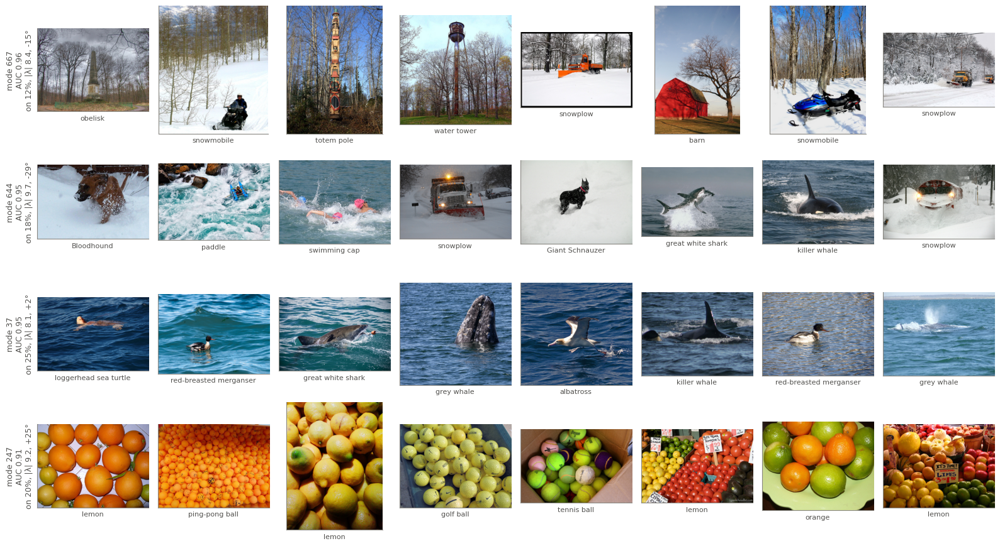

,AUC,on for snowy,on for normal,on for validation,|λ|,angle
mode,,,,,,
667,0.955,0.953,0.134,0.116,8.373,-14.749000
644,0.949,0.930,0.223,0.180,9.679,-28.657000
37,0.946,0.969,0.300,0.252,8.092,1.914000
247,0.909,0.853,0.146,0.196,9.230,25.048000
7,0.882,0.791,0.051,0.234,9.694,26.167999
461,0.818,0.721,0.183,0.174,8.165,13.071000


In [10]:
def get_aucs(activity, labels):
    return torch.tensor([roc_auc_score(labels.numpy(), activity[:, m].numpy()) if activity[:, m].any() else 0.5 for m in range(activity.shape[1])])


def show_modes(shown, labels):
    fig, axes = plt.subplots(len(shown), 8, figsize=(16, 2.2 * len(shown)), squeeze=False)
    for row, mode, label in zip(axes, shown, labels):
        order = z6[:, mode].abs().argsort(descending=True)
        for ax, index in zip(row, order[~hidden[order]][:8].tolist()):
            image = images[index]["image"].convert("RGB")
            image.thumbnail((256, 256))
            ax.imshow(np.asarray(image))
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            ax.set_xlabel(class_names[val_y[index]][:22], fontsize=8, color=INK)
        row[0].set_ylabel(f"mode {mode}\n{label}\non {usage[mode].item():.0%}, |λ| {size[mode]:.1f}, {angle[mode]:+.0f}°", fontsize=9, color=INK)
    fig.tight_layout()
    plt.show()


snow_activity = snow_z.abs()
aucs = get_aucs(snow_activity, is_snowy)
eligible = usage < 0.9
SNOW_MODES = [m for m in aucs.argsort(descending=True).tolist() if eligible[m]][:NUM_SNOW_MODES]

# Pick on one half of the snow test, score on the other, so the AUC isn't measured where the mode was picked
fold = torch.arange(len(y)) % 2
for half in [0, 1]:
    pick, test = fold == half, fold != half
    best = int(torch.where(eligible, get_aucs(snow_activity[pick], is_snowy[pick]), 0.0).argmax())
    print(f"Half {half}: picks mode {best}, AUC on the other half {roc_auc_score(is_snowy[test].numpy(), snow_activity[test, best].numpy()):.3f}")

show_modes(SNOW_MODES[:4], [f"AUC {aucs[m]:.2f}" for m in SNOW_MODES[:4]])
pd.DataFrame(
    {
        "AUC": aucs[SNOW_MODES].numpy(),
        "on for snowy": (snow_activity[is_snowy][:, SNOW_MODES] > 0).double().mean(dim=0).numpy(),
        "on for normal": (snow_activity[~is_snowy][:, SNOW_MODES] > 0).double().mean(dim=0).numpy(),
        "on for validation": usage[SNOW_MODES].numpy(),
        "|λ|": size[SNOW_MODES].numpy(),
        "angle": angle[SNOW_MODES].numpy(),
    },
    index=pd.Index(SNOW_MODES, name="mode"),
).round(3)

##### Editing one snow mode: size or turn

For each of the top three snow modes, the KAE's accuracy on the 129 snowy images as we turn the mode's eigenvalue by an angle, keeping its size. A turn of 0° is K as trained, and a turn of 180° is the same as multiplying `λ` by -1. The orange line is the mode removed (`λ` to 0).

Then a check that the best turn isn't picked where it is scored: we pick it on the even snowy images and score it on the odd ones.

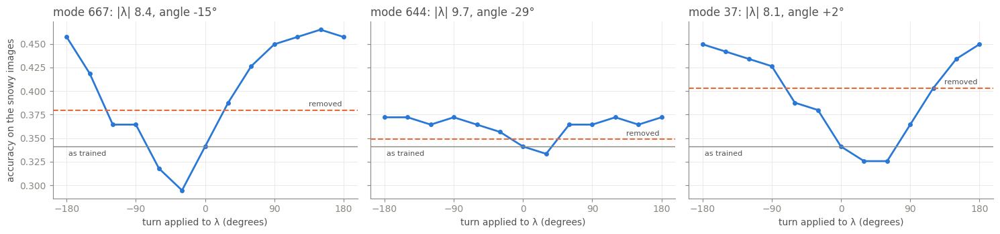

,"best turn, picked on even images",odd images: as trained,odd images: removed,odd images: best turn,all snowy: fixed by the best turn,all snowy: broken by the best turn,all snowy: fixed by removal,all snowy: broken by removal
mode,,,,,,,,
667,90,0.359,0.406,0.438,15,1,6,1
644,-180,0.359,0.406,0.422,8,4,4,3
37,-180,0.359,0.422,0.469,14,0,8,0


In [11]:
TURNS = list(range(-180, 181, 30))
snowy_z, snowy_truth = snow_z[is_snowy], y[is_snowy]
as_trained = kae_right[is_snowy]
even = torch.arange(len(snowy_truth)) % 2 == 0

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
rows = []
for ax, mode in zip(axes, SNOW_MODES[:3]):
    right = {degrees: head.classify(edit(snowy_z, {mode: turn(degrees)})) == snowy_truth for degrees in TURNS}
    removed = head.classify(edit(snowy_z, {mode: 0.0})) == snowy_truth
    accuracy = [right[degrees].double().mean().item() for degrees in TURNS]
    ax.plot(TURNS, accuracy, color=BLUE, lw=2, marker="o", ms=4)
    ax.axhline(removed.double().mean().item(), color=ORANGE, lw=1.5, ls="--")
    ax.axhline(as_trained.double().mean().item(), color=MUTED, lw=1)
    ax.annotate("removed", (180, removed.double().mean().item()), xytext=(-2, 4), textcoords="offset points", fontsize=8, color=INK, ha="right")
    ax.annotate("as trained", (-180, as_trained.double().mean().item()), xytext=(2, -10), textcoords="offset points", fontsize=8, color=INK)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xlabel("turn applied to λ (degrees)")
    ax.set_title(f"mode {mode}: |λ| {size[mode]:.1f}, angle {angle[mode]:+.0f}°", loc="left", color=INK)

    best = max(TURNS[:-1], key=lambda degrees: right[degrees][even].double().mean().item())
    rows.append(
        {
            "mode": mode,
            "best turn, picked on even images": best,
            "odd images: as trained": as_trained[~even].double().mean().item(),
            "odd images: removed": removed[~even].double().mean().item(),
            "odd images: best turn": right[best][~even].double().mean().item(),
            "all snowy: fixed by the best turn": int((~as_trained & right[best]).sum()),
            "all snowy: broken by the best turn": int((as_trained & ~right[best]).sum()),
            "all snowy: fixed by removal": int((~as_trained & removed).sum()),
            "all snowy: broken by removal": int((as_trained & ~removed).sum()),
        }
    )
axes[0].set_ylabel("accuracy on the snowy images")
fig.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("mode").round(3)

##### Editing several snow modes at once

Snow is spread over several modes, so we edit the top 1 to 6 of them together. An image is fixed if its answer goes from wrong to right, and broken if it goes from right to wrong. On the left, the 129 snowy images. On the right, every validation image that keeps at least one of the edited modes, which is what the edit costs on ordinary images, as K is shared by every image.

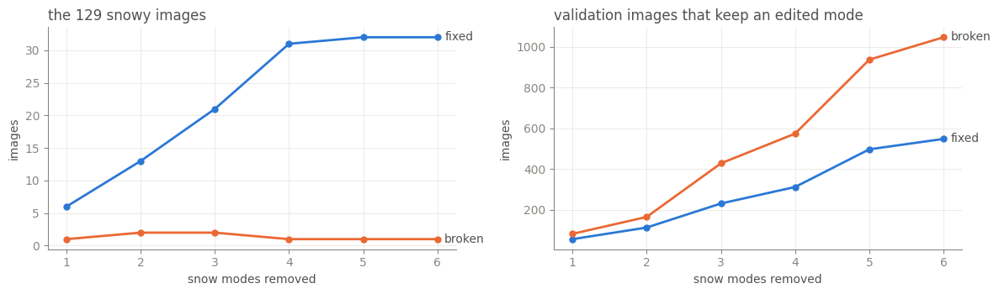

As trained: snowy 0.341, normal 0.677; DINOv3: snowy 0.860, normal 0.829


accuracy, snowy  accuracy, normal  snowy: fixed  snowy: broken  validation images touched  validation: fixed  validation: broken
modes edited edit                                                                                                                                         
1            removed                0.380             0.677             6              1                       5825                 56                  82
             turned +90°            0.450             0.677            15              1                       5825                 83                 108
             turned -90°            0.364             0.680             6              3                       5825                 64                 114
             turned 180°            0.457             0.680            16              1                       5825                 92                 155
2            removed                0.426             0.677            13              2                      13049                113                 165
             turned +90°            0.496             0.677            22              2                      13049                150                 215
             turned -90°            0.357             0.680             6              4                      13049                138                 242
             turned 180°            0.535             0.677            28              3                      13049                194                 350
3            removed                0.488             0.677            21              2                      20407                231                 428
             turned +90°            0.519             0.674            25              2                      20407                297                 707
             turned -90°            0.450             0.680            16              2                      20407                276                 610
             turned 180°            0.597             0.680            37              4                      20407                349                 985
4            removed                0.574             0.677            31              1                      25815                312                 574
             turned +90°            0.519             0.674            28              5                      25815                375                 920
             turned -90°            0.519             0.680            24              1                      25815                368                 839
             turned 180°            0.589             0.677            37              5                      25815                472                1334
5            removed                0.581             0.677            32              1                      30716                497                 937
             turned +90°            0.543             0.674            31              5                      30716                565                1508
             turned -90°            0.543             0.680            29              3                      30716                569                1352
             turned 180°            0.581             0.677            36              5                      30716                658                2369
6            removed                0.581             0.677            32              1                      33016                548                1047
             turned +90°            0.527             0.674            30              6                      33016                614                1748
             turned -90°            0.589             0.680            34              2                      33016                640                1604
             turned 180°            0.589             0.677            37              5                      33016                742                2

In [12]:
EDITS = {"removed": 0.0, "turned +90°": turn(90), "turned -90°": turn(-90), "turned 180°": -1.0}
rows = []
for count in range(1, NUM_SNOW_MODES + 1):
    chosen = SNOW_MODES[:count]
    touched = kept[:, chosen].any(dim=1)
    val_before = answers[touched] == val_y[touched]
    for label, factor in EDITS.items():
        changes = {mode: factor for mode in chosen}
        right = head.classify(edit(snow_z, changes)) == y
        val_right = head.classify(edit(z6[touched], changes)) == val_y[touched]
        rows.append(
            {
                "modes edited": count,
                "edit": label,
                "accuracy, snowy": right[is_snowy].double().mean().item(),
                "accuracy, normal": right[~is_snowy].double().mean().item(),
                "snowy: fixed": int((~kae_right & right & is_snowy).sum()),
                "snowy: broken": int((kae_right & ~right & is_snowy).sum()),
                "validation images touched": int(touched.sum()),
                "validation: fixed": int((~val_before & val_right).sum()),
                "validation: broken": int((val_before & ~val_right).sum()),
            }
        )
several = pd.DataFrame(rows)

removal = several[several["edit"] == "removed"].set_index("modes edited")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, prefix, title in [(axes[0], "snowy", "the 129 snowy images"), (axes[1], "validation", "validation images that keep an edited mode")]:
    for column, label, color in [(f"{prefix}: fixed", "fixed", BLUE), (f"{prefix}: broken", "broken", ORANGE)]:
        ax.plot(removal.index, removal[column], color=color, lw=2, marker="o", ms=5)
        ax.annotate(label, (removal.index[-1], removal[column].iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, va="center")
    ax.set_xlabel("snow modes removed")
    ax.set_ylabel("images")
    ax.set_title(title, loc="left", color=INK)
fig.tight_layout()
plt.show()

print(f"As trained: snowy {kae_right[is_snowy].double().mean():.3f}, normal {kae_right[~is_snowy].double().mean():.3f}; DINOv3: snowy {true_right[is_snowy].double().mean():.3f}, normal {true_right[~is_snowy].double().mean():.3f}")
several.set_index(["modes edited", "edit"]).round(3)

The modes above were picked on the images they are scored on. As a check, we rank the modes by AUC on one half of the snow test, remove the top 4, and score the snowy images of the other half.

In [13]:
rows = []
for half in [0, 1]:
    pick, test = fold == half, (fold != half) & is_snowy
    half_aucs = torch.where(eligible, get_aucs(snow_activity[pick], is_snowy[pick]), 0.0)
    chosen = half_aucs.argsort(descending=True)[:4].tolist()
    right = head.classify(edit(snow_z[test], {mode: 0.0 for mode in chosen})) == y[test]
    rows.append(
        {
            "picked on half": half,
            "modes": chosen,
            "other half, as trained": kae_right[test].double().mean().item(),
            "other half, 4 modes removed": right.double().mean().item(),
            "fixed": int((~kae_right[test] & right).sum()),
            "broken": int((kae_right[test] & ~right).sum()),
        }
    )
pd.DataFrame(rows).set_index("picked on half").round(3)

,modes,"other half, as trained","other half, 4 modes removed",fixed,broken
picked on half,,,,,
0,"[667, 37, 247, 644]",0.359,0.562,13,0
1,"[644, 37, 667, 247]",0.323,0.585,18,1


Which snowy images removing the top 4 snow modes fixes, with the KAE's answer before and after, and the classes it breaks most on validation.

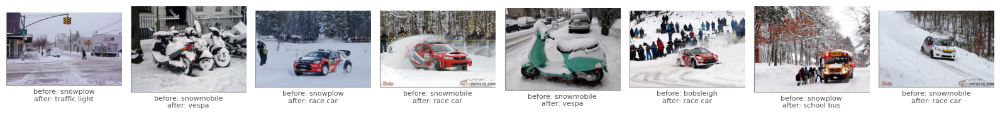

Snowy images still wrong after the edit: [('snowplow', 7), ('bobsleigh', 4), ('half-track', 3), ('tow truck', 3)]


,validation images broken
snowplow,15
snorkel,14
swimming cap,13
promontory,12
otter,11
soccer ball,9
drilling rig,9
red-breasted merganser,9
killer whale,9
albatross,9


In [14]:
changes = {mode: 0.0 for mode in SNOW_MODES[:4]}
after_answers = head.classify(edit(snow_z, changes))
fixed = (is_snowy & ~kae_right & (after_answers == y)).nonzero()[:, 0]
first_snowy = int((~is_snowy).sum())

shown = fixed[torch.randperm(len(fixed))[:8]]
if len(shown):
    fig, axes = plt.subplots(1, len(shown), figsize=(2 * len(shown), 3.2), squeeze=False)
    for ax, index in zip(axes[0], shown.tolist()):
        image = Image.open(paths[index - first_snowy]).convert("RGB")
        image.thumbnail((256, 256))
        ax.imshow(np.asarray(image))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.set_xlabel(f"before: {class_names[snow_answers[index]][:18]}\nafter: {class_names[after_answers[index]][:18]}", fontsize=8, color=INK)
    fig.tight_layout()
    plt.show()

touched = kept[:, SNOW_MODES[:4]].any(dim=1)
truth, before = val_y[touched], answers[touched]
after = head.classify(edit(z6[touched], changes))
broken = (before == truth) & (after != truth)
print(f"Snowy images still wrong after the edit: {Counter(class_names[c] for c in after_answers[is_snowy & (after_answers != y)].tolist()).most_common(4)}")
pd.Series(Counter(class_names[c] for c in truth[broken].tolist()), dtype=int).sort_values(ascending=False).head(10).rename("validation images broken").to_frame()

##### Is K wrong about the snow modes?

Removing the snow modes fixes snowy images. That would be a repair if K overdid snow on these images. We check it the same way as above, on the snow test: the top 4 snow modes take their true block-12 value while K handles the rest, and the other way round. Then how the snow modes really move from block 6 to block 12 on the snowy vehicles, against the snowplows and snowmobiles of validation.

In [15]:
def get_snow_scores(z_end):
    right = head.classify(decode(z_end)) == y
    return {"accuracy, snowy": right[is_snowy].double().mean().item(), "accuracy, normal": right[~is_snowy].double().mean().item()}


chosen = SNOW_MODES[:4]
predicted = eigenvalues * snow_z
only_snow, all_but_snow = predicted.clone(), snow_z12.clone()
only_snow[:, chosen] = snow_z12[:, chosen]
all_but_snow[:, chosen] = predicted[:, chosen]
display(
    pd.DataFrame(
        {
            "K as trained": get_snow_scores(predicted),
            "true values for the top 4 snow modes, K for the rest": get_snow_scores(only_snow),
            "K for the top 4 snow modes, true values for the rest": get_snow_scores(all_but_snow),
            "true values for every mode (no K)": get_snow_scores(snow_z12),
            "K's size, true turn, every mode": get_snow_scores(mix(snow_z, snow_z12, "turn")),
            "K's turn, true size, every mode": get_snow_scores(mix(snow_z, snow_z12, "size")),
        }
    ).T.round(3)
)

assert (class_names[802], class_names[803]) == ("snowmobile", "snowplow")
snow_classes = (val_y == 802) | (val_y == 803)
image_groups = {
    "snowy vehicles": (snow_z[is_snowy], snow_z12[is_snowy]),
    "snowplows and snowmobiles in validation": (z6[snow_classes], z12[snow_classes]),
    "all validation": (z6, z12),
}
rows = []
for mode in chosen:
    for label, (start, end) in image_groups.items():
        on = start[:, mode] != 0
        a, b = start[on, mode], end[on, mode]
        pooled = (b * a.conj()).sum()
        rows.append(
            {
                "mode": mode,
                "images": label,
                "keep the mode": int(on.sum()),
                "|λ|": size[mode].item(),
                "angle": angle[mode].item(),
                "size at block 6": a.abs().median().item(),
                "measured gain": (b.abs() / a.abs()).median().item(),
                "measured turn": math.degrees(torch.angle(pooled).item()),
            }
        )
pd.DataFrame(rows).set_index(["mode", "images"]).round(2)

,"accuracy, snowy","accuracy, normal"
K as trained,0.341,0.677
"true values for the top 4 snow modes, K for the rest",0.388,0.677
"K for the top 4 snow modes, true values for the rest",0.698,0.806
true values for every mode (no K),0.721,0.803
"K's size, true turn, every mode",0.558,0.783
"K's turn, true size, every mode",0.512,0.766


keep the mode   |λ|  angle  size at block 6  measured gain  measured turn
mode images                                                                                                            
667  snowy vehicles                                     123  8.37 -14.75             0.52           7.84         -11.50
     snowplows and snowmobiles in validation             92  8.37 -14.75             0.51           8.32         -14.47
     all validation                                    5825  8.37 -14.75             0.18           7.33         -14.74
644  snowy vehicles                                     120  9.68 -28.66             0.34           8.37         -29.92
     snowplows and snowmobiles in validation             88  9.68 -28.66             0.32           9.61         -27.91
     all validation                                    8980  9.68 -28.66             0.16           8.09         -28.13
37   snowy vehicles                                     125  8.09   1.91             0.43           7.03           2.19
     snowplows and snowmobiles in validation             95  8.09   1.91             0.56           7.70           3.29
     all validation                                   12597  8.09   1.91             0.20           7.49           1.56
247  snowy vehicles                                     110  9.23  25.05             0.25           7.63          23.50
     snowplows and snowmobiles in validation             89  9.23  25.05             0.31           9.26          24.82
     all validation                                    9814  9.23  25.05             0.16           7.68          24.76

##### Every mode: coherence, and what removing it does

For each mode kept on at least 0.5% of images:
- **coherence**: how alike its top 16 validation images are, as the mean cosine between their DINOv3 final features. A mode passes if it beats 99% of random sets of 16 images. This is a low bar: 16 images of one class score far higher. So passing means "more alike than chance", not "interpretable".
- **removal**: we set `λ` to 0 and count, over every validation image that keeps the mode, the answers that go from wrong to right (fixed) and from right to wrong (broken).

Random sets of 16: 99th percentile 0.024. Sets of 16 from one class: median 0.327
95% of 455 modes beat random
Summed over modes, removal fixes 51909 answers and breaks 97332; 36 modes fix more than they break


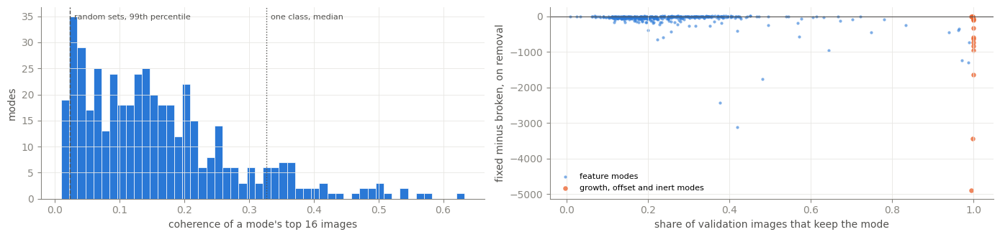

,modes,beat_random
classes in top 16,,
1-3 classes,13,1.000
4-8 classes,124,1.000
9-16 classes,318,0.934


In [16]:
true_embeddings = head.embed(val_x[:, 1])


def get_coherence(indices):
    """Mean cosine between the DINOv3 features of a set of images, leaving out each image with itself."""

    similarity = true_embeddings[indices] @ true_embeddings[indices].T
    n = len(indices)
    return ((similarity.sum() - n) / (n * (n - 1))).item()


random_sets = np.array([get_coherence(torch.randperm(len(val_y))[:16]) for _ in range(1_000)])
class_sets = np.array([get_coherence((val_y == c).nonzero()[:, 0][:16]) for c in range(1_000)])
threshold = np.quantile(random_sets, 0.99)

rows = []
for mode in modes.index.tolist():
    top = z6[:, mode].abs().topk(16).indices
    on = kept[:, mode]
    before, truth = answers[on], val_y[on]
    after = head.classify(edit(z6[on], {mode: 0.0}))
    rows.append(
        {
            "mode": mode,
            "coherence": get_coherence(top),
            "classes in top 16": len(set(val_y[top].tolist())),
            "hidden in top 16": int(hidden[top].sum()),
            "top classes": ", ".join(f"{class_names[c][:16]} {k}" for c, k in Counter(val_y[top].tolist()).most_common(3)),
            "fixed": int(((before != truth) & (after == truth)).sum()),
            "broken": int(((before == truth) & (after != truth)).sum()),
            "answers changed": (before != after).double().mean().item(),
        }
    )
table = modes.join(pd.DataFrame(rows).set_index("mode"))
table["net"] = table["fixed"] - table["broken"]

print(f"Random sets of 16: 99th percentile {threshold:.3f}. Sets of 16 from one class: median {np.median(class_sets):.3f}")
print(f"{(table['coherence'] > threshold).mean():.0%} of {len(table)} modes beat random")
print(f"Summed over modes, removal fixes {table['fixed'].sum()} answers and breaks {table['broken'].sum()}; {int((table['net'] > 0).sum())} modes fix more than they break")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
axes[0].hist(table["coherence"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
for value, label, style in [(threshold, "random sets, 99th percentile", "--"), (np.median(class_sets), "one class, median", ":")]:
    axes[0].axvline(value, color=INK, lw=1, ls=style)
    axes[0].annotate(label, (value, axes[0].get_ylim()[1]), xytext=(4, -12), textcoords="offset points", fontsize=8, color=INK)
axes[0].set_xlabel("coherence of a mode's top 16 images")
axes[0].set_ylabel("modes")
feature = table["group"] == "feature"
axes[1].scatter(table.loc[feature, "kept"], table.loc[feature, "net"], s=9, color=BLUE, alpha=0.6, lw=0, label="feature modes")
axes[1].scatter(table.loc[~feature, "kept"], table.loc[~feature, "net"], s=22, color=ORANGE, alpha=0.8, lw=0, label="growth, offset and inert modes")
axes[1].axhline(0, color=INK, lw=0.8)
axes[1].set_xlabel("share of validation images that keep the mode")
axes[1].set_ylabel("fixed minus broken, on removal")
axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

COLUMNS = ["group", "|λ|", "angle", "kept", "coherence", "classes in top 16", "fixed", "broken", "net", "answers changed", "top classes"]
table.groupby(pd.cut(table["classes in top 16"], [0, 3, 8, 16], labels=["1-3 classes", "4-8 classes", "9-16 classes"]), observed=True)["coherence"].agg(modes="size", beat_random=lambda c: (c > threshold).mean()).round(3)

The modes whose removal breaks the most answers, and the ones whose removal fixes more than it breaks.

In [17]:
display(table.sort_values("net").head(12)[COLUMNS].round(3))
table.sort_values("net", ascending=False).head(8)[COLUMNS].round(3)

,group,|λ|,angle,kept,coherence,classes in top 16,fixed,broken,net,answers changed,top classes
mode,,,,,,,,,,,
77,growth,14.431,8.145,0.995,0.090,14,1522,6410,-4888,0.308,"airship 3, slot machine 1, goose 1"
331,growth,18.942,10.463,0.999,0.066,14,1508,4943,-3435,0.263,"echidna 3, knee pad 1, white-headed cap 1"
179,feature,6.632,18.054,0.419,0.436,6,384,3500,-3116,0.329,"collie 6, Pomeranian 5, Keeshond 2"
810,feature,7.466,-12.817,0.377,0.203,13,481,2915,-2434,0.315,"dhole 3, cougar 2, husky 1"
456,feature,7.159,-9.113,0.482,0.172,12,579,2334,-1755,0.247,"Great Pyrenees d 3, husky 2, Greater Swiss Mo 2"
338,offset,2.968,-94.217,1.000,0.208,8,1627,3269,-1642,0.205,"dishcloth 6, honeycomb 3, scarf 2"
626,feature,8.296,25.200,0.987,0.356,5,1323,2627,-1304,0.171,"dishcloth 12, chain mail 1, prayer rug 1"
789,feature,8.602,17.312,0.972,0.075,14,1021,2255,-1234,0.141,"Cocker Spaniel 2, Golden Retriever 2, knee pad 1"
144,offset,3.143,-69.470,1.000,0.121,12,1334,2293,-959,0.155,"window screen 2, corn 2, corn cob 2"


,group,|λ|,angle,kept,coherence,classes in top 16,fixed,broken,net,answers changed,top classes
mode,,,,,,,,,,,
757,feature,1.933,4.880,0.344,0.139,10,27,16,11,0.005,"window screen 5, shoji screen / r 3, cannon 1"
84,feature,2.506,-4.734,0.365,0.050,13,32,23,9,0.008,"prayer rug 3, sock 2, leafhopper 1"
604,feature,3.219,-6.947,0.452,0.022,15,56,47,9,0.009,"window screen 2, wallet 1, balloon 1"
364,feature,1.961,-2.248,0.274,0.143,9,14,5,9,0.004,"dishcloth 7, honeycomb 2, baby bib 1"
958,feature,1.638,-0.824,0.258,0.029,16,14,7,7,0.004,"water bottle 1, macaque 1, howler monkey 1"
319,feature,4.154,24.406,0.191,0.254,8,26,20,6,0.011,"ambulance 4, minibus 4, minivan 3"
654,feature,2.997,-4.120,0.403,0.039,15,31,25,6,0.007,"solar thermal co 2, pillow 1, thatched roof 1"
773,feature,2.583,6.218,0.273,0.049,14,19,13,6,0.005,"killer whale 3, folding chair 1, pillow 1"


##### What some modes fire on

The 8 validation images where each mode is most active (by size at block 6), with their ImageNet class underneath. First the most coherent feature modes whose top 16 images span at least 9 classes, picked automatically, so these are modes that group images across classes. Then modes drawn at random from the feature modes, so that the gallery isn't only the best picks.

80 modes mostly fire on hidden images and are left out of the galleries


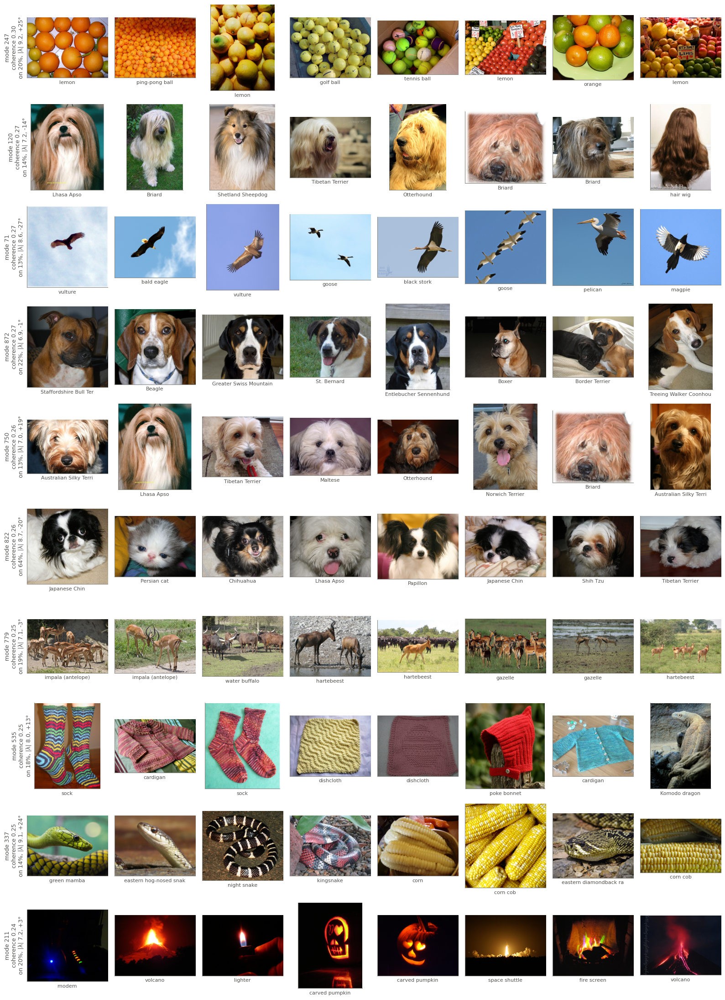

In [18]:
showable = table["hidden in top 16"] < 4
print(f"{int((~showable).sum())} modes mostly fire on hidden images and are left out of the galleries")
cross_class = table[(table["classes in top 16"] >= 9) & feature & showable].sort_values("coherence", ascending=False)
picked = cross_class.index[:NUM_COHERENT].tolist()
show_modes(picked, [f"coherence {cross_class.loc[m, 'coherence']:.2f}" for m in picked])

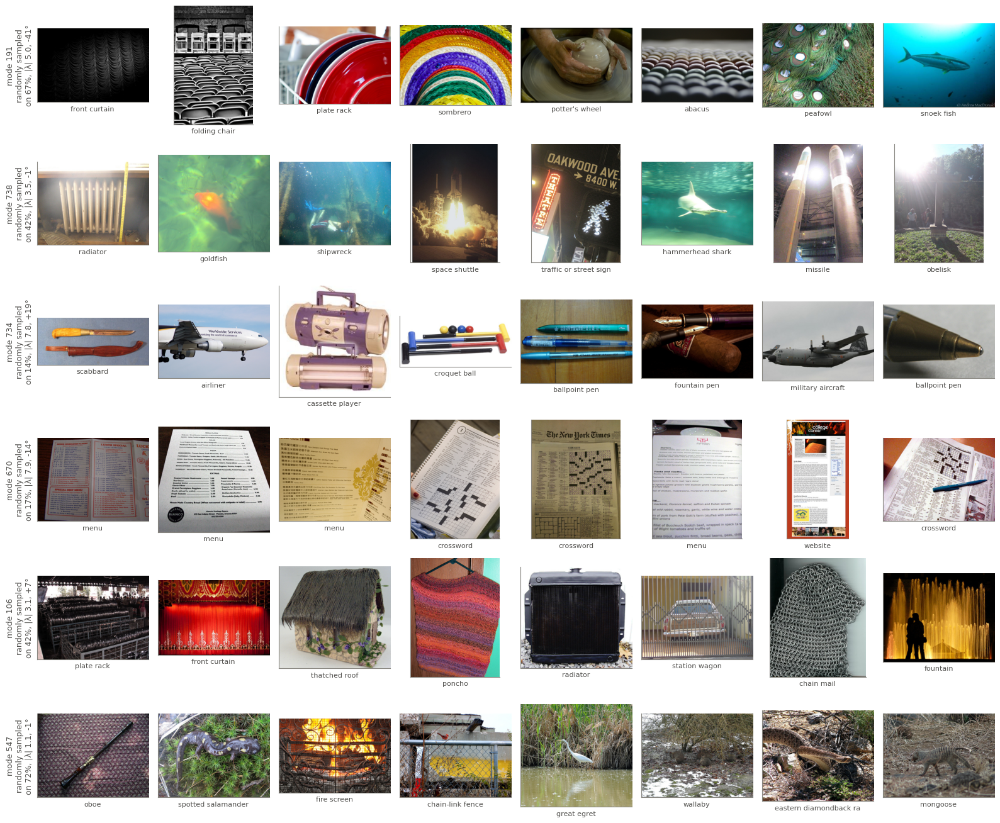

In [19]:
candidates = table.index[feature & showable].to_numpy()
sample = candidates[torch.randperm(len(candidates))[:NUM_RANDOM].numpy()].tolist()
show_modes(sample, ["randomly sampled"] * NUM_RANDOM)

The feature modes whose removal breaks the most answers, then the growth modes and the two offset modes with the most energy at block 6. The last four are on for every image, so their top images only say where they are largest.

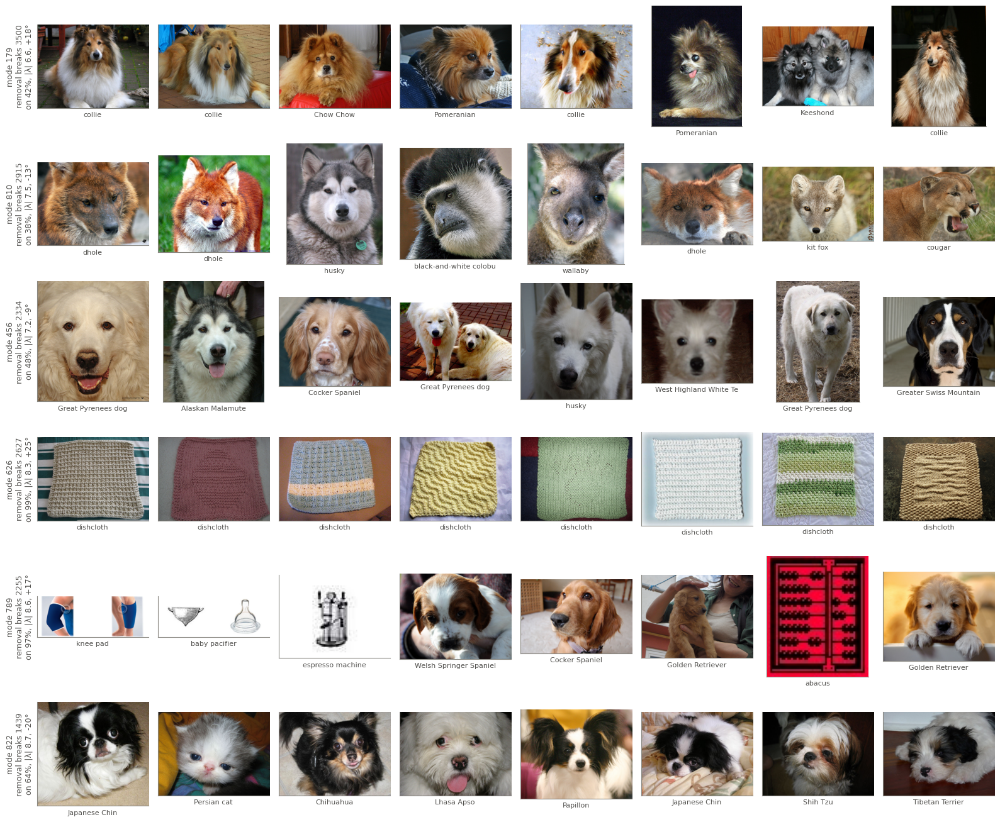

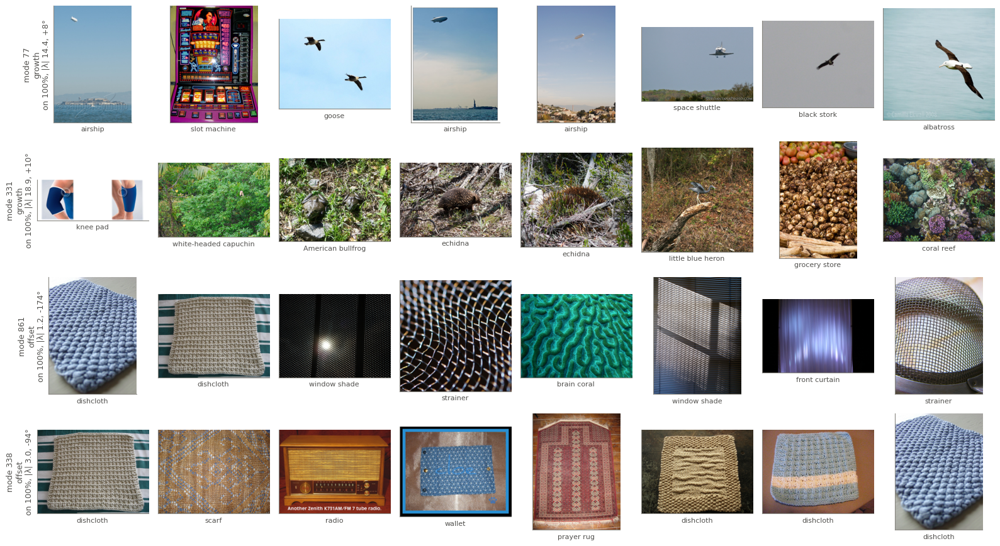

In [20]:
needed = table[feature & showable].sort_values("net").index[:6].tolist()
show_modes(needed, [f"removal breaks {table.loc[m, 'broken']}" for m in needed])

constant = [int(m) for m in np.flatnonzero(group == "growth")] + [int(m) for m in share6.argsort(descending=True).tolist() if group[m] == "offset"][:2]
show_modes(constant, [group[m] for m in constant])

##### Size against turn, over many modes

Is turning a mode a different edit from changing its size? For 40 feature modes drawn at random from those kept on 3% to 30% of images, we apply each edit on up to 2,000 images that keep the mode and measure: how many answers change, the change in accuracy, how far the DINOv3 feature moves (1 - cosine), and the direction of that move against the move made by doubling the mode's size (cosine: 1 means the edit acts like scaling up, -1 like scaling down, 0 means a new direction). Each number is the median over the 40 modes.

In [21]:
MANY_EDITS = {
    "size x0 (removed)": 0.0,
    "size x0.5": 0.5,
    "size x2": 2.0,
    "turn +45°": turn(45),
    "turn -45°": turn(-45),
    "turn +90°": turn(90),
    "turn -90°": turn(-90),
    "turn 180° (x-1)": -1.0,
}
pool = table.index[feature & (table["kept"] > 0.03) & (table["kept"] < 0.3)].to_numpy()
sampled = pool[torch.randperm(len(pool))[:40].numpy()].tolist()
per_edit = {label: [] for label in MANY_EDITS}
for mode in sampled:
    on = kept[:, mode].nonzero()[:, 0]
    on = on[torch.randperm(len(on))[:2_000]]
    start, truth = z6[on], val_y[on]
    before = head.embed(decode(eigenvalues * start))
    doubled = head.embed(edit(start, {mode: 2.0})) - before
    for label, factor in MANY_EDITS.items():
        prediction = edit(start, {mode: factor})
        after, new_answers = head.embed(prediction), head.classify(prediction)
        per_edit[label].append(
            {
                "answers changed": (new_answers != answers[on]).double().mean().item(),
                "accuracy change": ((new_answers == truth).double().mean() - (answers[on] == truth).double().mean()).item(),
                "feature move (1 - cosine)": (1 - (after * before).sum(dim=-1)).median().item(),
                "direction against size x2 (cosine)": torch.nn.functional.cosine_similarity(after - before, doubled, dim=-1).median().item(),
            }
        )
pd.DataFrame({label: pd.DataFrame(rows).median() for label, rows in per_edit.items()}).T.round(3)

,answers changed,accuracy change,feature move (1 - cosine),direction against size x2 (cosine)
size x0 (removed),0.039,-0.002,0.001,-0.957
size x0.5,0.019,-0.000,0.000,-0.969
size x2,0.042,-0.002,0.002,1.000
turn +45°,0.027,-0.001,0.001,-0.362
turn -45°,0.027,-0.001,0.001,-0.342
turn +90°,0.053,-0.004,0.002,-0.649
turn -90°,0.051,-0.003,0.002,-0.652
turn 180° (x-1),0.078,-0.009,0.004,-0.930


##### By angle

The modes kept on at least 0.5% of images, grouped by the size of their angle. Medians within each group.

In [22]:
bins = pd.cut(table["angle"].abs(), [0, 5, 15, 45, 180], include_lowest=True)
by_angle = table.groupby(bins, observed=True).agg(
    modes=("kept", "size"),
    kept=("kept", "median"),
    size=("|λ|", "median"),
    coherence=("coherence", "median"),
    r_squared=("R²", "median"),
    answers_changed_on_removal=("answers changed", "median"),
)
by_angle.round(3)

,modes,kept,size,coherence,r_squared,answers_changed_on_removal
angle,,,,,,
"(-0.001, 5.0]",120,0.269,2.780,0.076,0.159,0.007
"(5.0, 15.0]",141,0.205,7.541,0.144,0.592,0.042
"(15.0, 45.0]",181,0.199,8.222,0.158,0.640,0.045
"(45.0, 180.0]",13,1.000,2.968,0.159,0.661,0.095


##### The modes every image keeps

16 modes are on for every image: 2 growth, 10 offset and 4 inert. The table says how fast each grows and how far it turns, ranked among the modes that are ever kept (rank 1 is the largest).

- **Size spread**: the spread of the mode's block-6 size over images, divided by its average. Near 0 means every image has the same amount.
- **Phase spread**: a mode's block-6 value is two numbers, so a point on a plane. This is how much the direction of that point varies over images. Near 0° means every image points the same way. Above 100° means images point all around the plane.

In [23]:
def get_phase_spread(mode):
    on = kept[:, mode]
    together = torch.exp(1j * torch.angle(z6[on, mode])).mean().abs().item()
    return math.degrees(math.sqrt(max(-2 * math.log(together), 0)))


def get_size_spread(mode):
    sizes = z6[kept[:, mode], mode].abs()
    return (sizes.std() / sizes.mean()).item()


ever_kept = ~never
rows = []
for name in ["growth", "offset", "inert"]:
    for mode in np.flatnonzero(group == name).tolist():
        rows.append(
            {
                "mode": mode,
                "group": name,
                "|λ|": size[mode].item(),
                "|λ| rank": int((size[ever_kept] > size[mode]).sum()) + 1,
                "|angle|°": angle[mode].abs().item(),
                "angle rank": int((angle[ever_kept].abs() > angle[mode].abs()).sum()) + 1,
                "size spread": get_size_spread(mode),
                "phase spread°": get_phase_spread(mode),
            }
        )
always_on = pd.DataFrame(rows).set_index("mode")
feature_modes = np.flatnonzero(group == "feature").tolist()
often = [mode for mode in feature_modes if usage[mode] >= 0.005]
print(f"{int(ever_kept.sum())} modes are ever kept. Feature modes: median |λ| {size[feature_modes].median():.2f}, median |angle| {angle[feature_modes].abs().median():.1f}°,")
print(f"median size spread {np.median([get_size_spread(mode) for mode in often]):.2f}, median phase spread {np.median([get_phase_spread(mode) for mode in often]):.1f}° (modes kept on at least 0.5% of images)")
always_on.round(2)

457 modes are ever kept. Feature modes: median |λ| 7.62, median |angle| 12.1°,


median size spread 0.47, median phase spread 41.8° (modes kept on at least 0.5% of images)


,group,|λ|,|λ| rank,|angle|°,angle rank,size spread,phase spread°
mode,,,,,,,
77,growth,14.43,2,8.14,282,0.54,119.67
331,growth,18.94,1,10.46,244,0.40,128.63
117,offset,3.49,324,57.58,9,0.28,14.43
144,offset,3.14,329,69.47,8,0.12,8.89
338,offset,2.97,341,94.22,4,0.09,4.96
533,offset,1.21,430,80.06,6,0.19,9.88
560,offset,2.91,345,71.05,7,0.18,6.45
652,offset,2.16,380,163.06,2,0.14,12.13
746,offset,0.74,456,14.37,201,0.30,10.83


##### Why the offset modes turn

Both blocks go through one shared standardization, so the average block-6 state and the average block-12 state sit on opposite sides of zero, at the same distance. Around those averages, block-12 states are spread about ten times wider than block-6 states. So from block 6 to block 12 the average has to flip its sign and keep its length, while the part that differs between images has to grow about tenfold.

In [24]:
state6, state12 = val_x[:, 0], val_x[:, 1]
mean_state6, mean_state12 = state6.mean(dim=0), state12.mean(dim=0)
spread6 = (state6 - mean_state6).pow(2).sum(dim=1).mean().sqrt().item()
spread12 = (state12 - mean_state12).pow(2).sum(dim=1).mean().sqrt().item()
print(f"cosine between the two average states: {torch.cosine_similarity(mean_state6, mean_state12, dim=0).item():.3f}")
print(f"spread at block 12 over spread at block 6: {spread12 / spread6:.2f}")
pd.DataFrame(
    {
        "length of the average state": [mean_state6.norm().item(), mean_state12.norm().item()],
        "spread of states around it": [spread6, spread12],
        "share of a state's energy that is the average": [(mean_state6.pow(2).sum() / state6.pow(2).sum(dim=1).mean()).item(), (mean_state12.pow(2).sum() / state12.pow(2).sum(dim=1).mean()).item()],
    },
    index=["block 6", "block 12"],
).round(2)

cosine between the two average states: -0.998
spread at block 12 over spread at block 6: 10.67


,length of the average state,spread of states around it,share of a state's energy that is the average
block 6,28.71,5.09,0.97
block 12,28.84,54.32,0.22


Decoding with only some of the modes, the rest set to zero. **Error left** is the squared error over the squared spread of states around their block's average, so 1 means "no better than the average state". The cosine compares the average output with the block's average state.

In [25]:
growth_modes, offset_modes, inert_modes = (np.flatnonzero(group == name).tolist() for name in ["growth", "offset", "inert"])
subsets = {
    "no modes": [],
    "10 offset": offset_modes,
    "2 growth": growth_modes,
    "feature modes only": feature_modes,
    "feature + growth": feature_modes + growth_modes,
    "feature + offset": feature_modes + offset_modes,
    "all modes": list(range(len(eigenvalues))),
}
rows = {}
for label, chosen in subsets.items():
    mask = torch.zeros(len(eigenvalues), dtype=torch.bool)
    mask[chosen] = True
    start, end = decode(z6 * mask), decode(eigenvalues * z6 * mask)
    rows[label] = {
        "block 6: error left": ((start - state6).pow(2).sum() / (state6 - mean_state6).pow(2).sum()).item(),
        "block 6: cosine with the average state": torch.cosine_similarity(start.mean(dim=0), mean_state6, dim=0).item(),
        "block 12: error left": ((end - state12).pow(2).sum() / (state12 - mean_state12).pow(2).sum()).item(),
        "block 12: cosine with the average state": torch.cosine_similarity(end.mean(dim=0), mean_state12, dim=0).item(),
        "probe accuracy": (head.classify(end) == val_y).double().mean().item(),
    }
pd.DataFrame(rows).T.round(3)

,block 6: error left,block 6: cosine with the average state,block 12: error left,block 12: cosine with the average state,probe accuracy
no modes,11.958,0.878,1.629,-0.878,0.001
10 offset,0.853,0.997,1.160,0.760,0.001
2 growth,11.927,0.878,1.555,-0.773,0.004
feature modes only,12.184,0.872,1.042,-0.347,0.515
feature + growth,12.098,0.872,0.943,-0.252,0.567
feature + offset,0.195,1.000,0.552,0.987,0.554
all modes,0.038,1.000,0.439,0.996,0.618


Are they constants? Each row changes one group of always-on modes in K's prediction and reports probe accuracy.

- **Same value for every image**: each mode takes its average value over images.
- **Angle set to 0**: the mode keeps its size at block 12 and loses its turn.
- For the growth modes, **average size, own direction** keeps where each image points on the mode's plane and gives every image the same size. **Own size, average direction** does the reverse.

In [26]:
prediction = eigenvalues * z6


def get_accuracy(z_end):
    return (head.classify(decode(z_end)) == val_y).double().mean().item()


rows = {"K as trained": {"probe accuracy": get_accuracy(prediction)}}
for label, chosen in [("10 offset modes", offset_modes), ("2 growth modes", growth_modes), ("4 inert modes", inert_modes)]:
    same, removed, straight = prediction.clone(), prediction.clone(), prediction.clone()
    same[:, chosen] = (eigenvalues[chosen] * z6[:, chosen].mean(dim=0)).expand(len(z6), -1)
    removed[:, chosen] = 0
    straight[:, chosen] = size[chosen] * z6[:, chosen]
    rows[f"{label}: same value for every image"] = {"probe accuracy": get_accuracy(same)}
    rows[f"{label}: removed"] = {"probe accuracy": get_accuracy(removed)}
    rows[f"{label}: angle set to 0"] = {"probe accuracy": get_accuracy(straight)}
for mode in growth_modes:
    own_direction, own_size = prediction.clone(), prediction.clone()
    own_direction[:, mode] = eigenvalues[mode] * z6[:, mode].abs().mean() * torch.exp(1j * torch.angle(z6[:, mode]))
    own_size[:, mode] = eigenvalues[mode] * z6[:, mode].abs() * torch.exp(1j * torch.angle(z6[:, mode].mean()))
    rows[f"mode {mode}: average size, own direction"] = {"probe accuracy": get_accuracy(own_direction)}
    rows[f"mode {mode}: own size, average direction"] = {"probe accuracy": get_accuracy(own_size)}
pd.DataFrame(rows).T.round(4)

,probe accuracy
K as trained,0.6178
10 offset modes: same value for every image,0.6128
10 offset modes: removed,0.5670
10 offset modes: angle set to 0,0.5207
2 growth modes: same value for every image,0.5581
2 growth modes: removed,0.5537
2 growth modes: angle set to 0,0.6022
4 inert modes: same value for every image,0.6178
4 inert modes: removed,0.6178
4 inert modes: angle set to 0,0.6178


##### What the growth modes hold

Each growth mode is a point on a plane that every image has. First, how well its two numbers are predicted by the main directions along which block-6 states differ from each other (their principal directions). Then, for each 45° slice of the plane, the classes whose images sit there most (the share of the class's total size that falls in the slice), and the images with the largest size in that slice.

In [27]:
centered6 = state6 - mean_state6
_, _, directions6 = torch.pca_lowrank(centered6, q=20, center=False, niter=4)
projected6 = centered6 @ directions6


def get_r2(target, design):
    design = torch.cat([design, torch.ones(len(design), 1)], dim=1)
    fit = design @ torch.linalg.lstsq(design, target).solution
    return (1 - (fit - target).pow(2).sum() / (target - target.mean(dim=0)).pow(2).sum()).item()


def get_class_share(mode):
    # The share of the spread of the mode's value over images that is between classes
    by_class = torch.zeros(1000, dtype=torch.cfloat).index_add_(0, val_y, z6[:, mode]) / 50
    within = (z6[:, mode] - by_class[val_y]).abs().pow(2).mean()
    return (1 - within / (z6[:, mode] - z6[:, mode].mean()).abs().pow(2).mean()).item()


rows = {}
for mode in growth_modes:
    value = torch.view_as_real(z6[:, mode].contiguous())
    rows[f"mode {mode}"] = {
        "R² from the top block-6 direction": get_r2(value, projected6[:, :1]),
        "from the top 5": get_r2(value, projected6[:, :5]),
        "from the top 20": get_r2(value, projected6[:, :20]),
        "share of its spread that is between classes": get_class_share(mode),
    }
print(f"feature modes: median share of spread between classes {np.median([get_class_share(mode) for mode in often]):.3f}")
pd.DataFrame(rows).T.round(3)

feature modes: median share of spread between classes 0.316


,R² from the top block-6 direction,from the top 5,from the top 20,share of its spread that is between classes
mode 77,0.061,0.492,0.905,0.577
mode 331,0.454,0.889,0.950,0.596


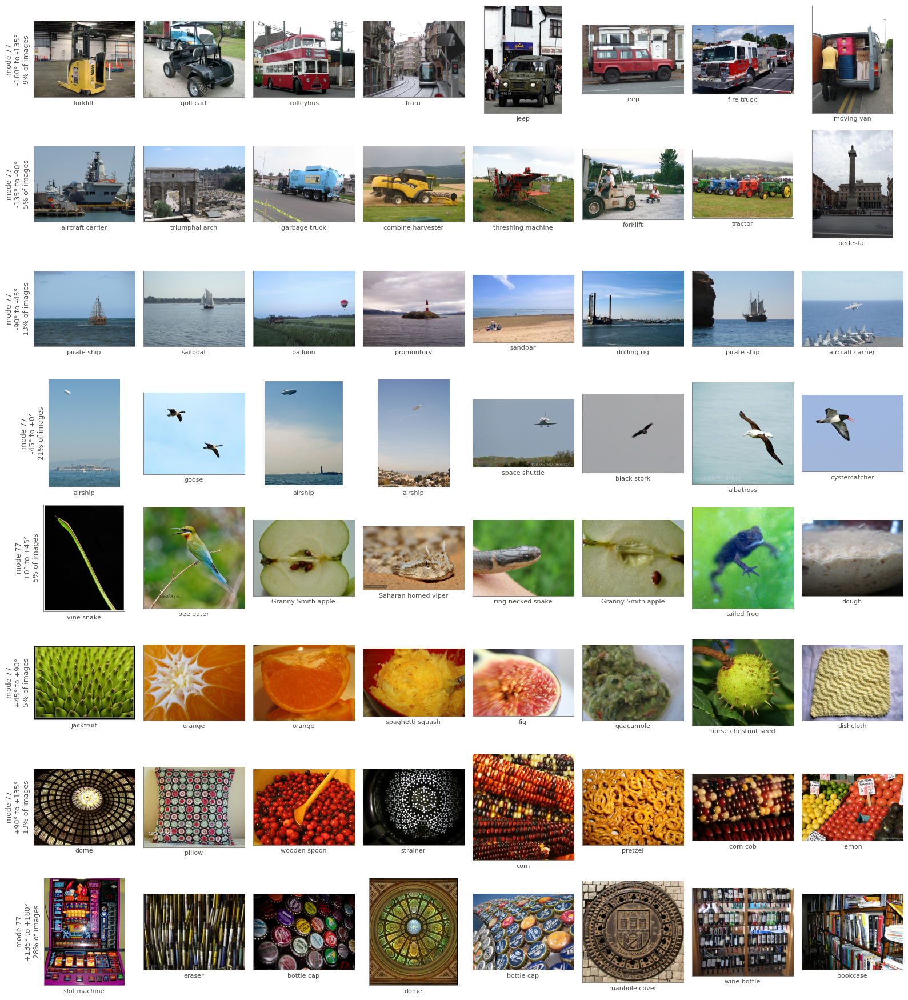

,share of images,classes that sit there most
direction,,
-180° to -135°,0.09,"triumphal arch, photocopier, trolleybus, golf cart, rickshaw, electric locomotive"
-135° to -90°,0.05,"palace, dock, monastery, bell tower, mosque, Afghan Hound"
-90° to -45°,0.13,"sailboat, trimaran, aircraft carrier, schooner, shipwreck, drilling rig"
-45° to +0°,0.21,"red-breasted merganser, black grouse, oystercatcher, ruddy turnstone, common redshank, kite (bird of prey)"
+0° to +45°,0.05,"jacamar, Saharan horned viper, goldfish, Granny Smith apple, sidewinder rattlesnake, vine snake"
+45° to +90°,0.05,"tree frog, cardoon, green mamba, orange, Carolina anole, eel"
+90° to +135°,0.13,"carbonara, gyromitra, artichoke, corn, earth star fungus, cheeseburger"
+135° to +180°,0.28,"vending machine, slot machine, carousel, pipe organ, disc brake, typewriter keyboard"


In [28]:
SLICE = 45
never_shown = set(HIDDEN_CLASSES.tolist())


def show_directions(mode):
    phase, sizes = torch.rad2deg(torch.angle(z6[:, mode])), z6[:, mode].abs()
    total = torch.zeros(1000).index_add_(0, val_y, sizes)
    lows = list(range(-180, 180, SLICE))
    fig, axes = plt.subplots(len(lows), 8, figsize=(16, 2.2 * len(lows)), squeeze=False)
    rows = []
    for row, low in zip(axes, lows):
        inside = (phase >= low) & (phase < low + SLICE)
        lift = torch.zeros(1000).index_add_(0, val_y[inside], sizes[inside]) / total
        top_classes = [c for c in lift.argsort(descending=True).tolist() if c not in never_shown][:6]
        rows.append({"direction": f"{low:+d}° to {low + SLICE:+d}°", "share of images": inside.double().mean().item(), "classes that sit there most": ", ".join(class_names[c] for c in top_classes)})
        for ax in row:
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
        shown = (inside & ~hidden).nonzero()[:, 0]
        for ax, index in zip(row, shown[sizes[shown].argsort(descending=True)][:8].tolist()):
            image = images[index]["image"].convert("RGB")
            image.thumbnail((256, 256))
            ax.imshow(np.asarray(image))
            ax.set_xlabel(class_names[val_y[index]][:22], fontsize=8, color=INK)
        row[0].set_ylabel(f"mode {mode}\n{low:+d}° to {low + SLICE:+d}°\n{inside.double().mean().item():.0%} of images", fontsize=9, color=INK)
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(rows).set_index("direction").round(2)


with pd.option_context("display.max_colwidth", 120):
    display(show_directions(growth_modes[0]))

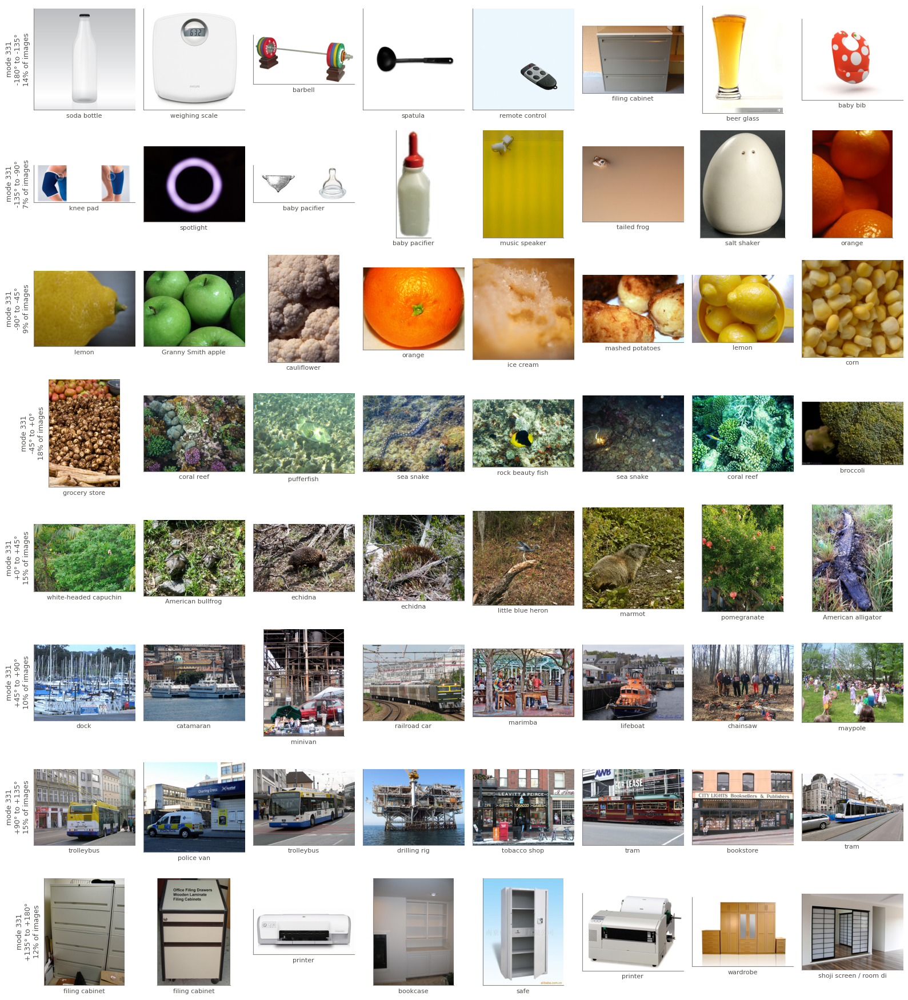

,share of images,classes that sit there most
direction,,
-180° to -135°,0.14,"can opener, corkscrew, parachute, whistle, knee pad, T-shirt"
-135° to -90°,0.07,"tiger shark, great white shark, jellyfish, hammerhead shark, Granny Smith apple, carved pumpkin"
-90° to -45°,0.09,"hamster, pot pie, jacamar, Persian cat, Siamese cat, mashed potatoes"
-45° to +0°,0.18,"brain coral, pufferfish, coral reef, lynx, guacamole, sea snake"
+0° to +45°,0.15,"gazelle, tusker, impala (antelope), bustard, Nile crocodile, bittern bird"
+45° to +90°,0.10,"maypole, carousel, moped, sawmill, tractor, butcher shop"
+90° to +135°,0.15,"ambulance, minibus, trolleybus, tram, vending machine, police van"
+135° to +180°,0.12,"photocopier, oscilloscope, Polaroid camera, home theater, CD player, chiffonier"


In [29]:
with pd.option_context("display.max_colwidth", 120):
    display(show_directions(growth_modes[1]))

##### DINOv3's own mistakes

Snow does not fool DINOv3, so where does it go wrong on ImageNet's validation images? First its wrong answers and the pairs of classes it mixes up most. The class number is shown as some classes share a name.

In [30]:
log_probs = head.get_log_probs(val_x[:, 1])
dino_wrong = true_answers != val_y
top5 = log_probs.topk(5).indices
in_top5 = (top5 == val_y[:, None]).any(dim=1)
print(f"DINOv3: accuracy {1 - dino_wrong.double().mean().item():.4f}, top-5 accuracy {in_top5.double().mean().item():.4f}, {int(dino_wrong.sum())} wrong answers")
print(f"of the wrong answers, the label is DINOv3's second choice for {(top5[:, 1] == val_y)[dino_wrong].double().mean().item():.3f} and among its top 5 for {in_top5[dino_wrong].double().mean().item():.3f}")

confusion = torch.zeros(1000, 1000, dtype=torch.long)
confusion.index_put_((val_y[dino_wrong], true_answers[dino_wrong]), torch.ones(int(dino_wrong.sum()), dtype=torch.long), accumulate=True)
both_ways = confusion + confusion.T
print(f"wrong answers inside a pair of classes mixed up at least 10 times: {(confusion[both_ways >= 10].sum() / dino_wrong.sum()).item():.3f}, over {int((both_ways >= 10).sum()) // 2} pairs")
print(f"KAE on the images DINOv3 gets right: {(answers == val_y)[~dino_wrong].double().mean().item():.4f}; on the images it gets wrong: {(answers == val_y)[dino_wrong].double().mean().item():.4f}")
print(f"on DINOv3's wrong answers the KAE gives the label {int((answers == val_y)[dino_wrong].sum())} times, DINOv3's wrong answer {int((answers == true_answers)[dino_wrong].sum())} times and a third answer {int(((answers != val_y) & (answers != true_answers))[dino_wrong].sum())} times")
rows = []
for index in confusion.flatten().argsort(descending=True).tolist():
    label, answer = divmod(index, 1000)
    if label in never_shown or answer in never_shown:
        continue
    rows.append({"label": f"{class_names[label]} ({label})", "DINOv3's answer": f"{class_names[answer]} ({answer})", "count, of 50": int(confusion[label, answer]), "the other way round": int(confusion[answer, label])})
    if len(rows) == 15:
        break
pd.DataFrame(rows)

DINOv3: accuracy 0.8394, top-5 accuracy 0.9681, 8032 wrong answers
of the wrong answers, the label is DINOv3's second choice for 0.515 and among its top 5 for 0.801
wrong answers inside a pair of classes mixed up at least 10 times: 0.211, over 104 pairs
KAE on the images DINOv3 gets right: 0.7114; on the images it gets wrong: 0.1287
on DINOv3's wrong answers the KAE gives the label 1034 times, DINOv3's wrong answer 3389 times and a third answer 3609 times


,label,DINOv3's answer,"count, of 50",the other way round
0,tights (638),one-piece bathing suit (639),34,10
1,laptop computer (620),notebook computer (681),30,15
2,sidewinder rattlesnake (68),Saharan horned viper (66),25,10
3,missile (657),missile (744),24,23
4,academic gown (400),graduation cap (667),23,10
5,missile (744),missile (657),23,24
6,collie (231),Shetland Sheepdog (230),20,0
7,Appenzeller Sennenhund (240),Greater Swiss Mountain Dog (238),19,3
8,Carolina anole (40),European green lizard (46),19,14
9,breastplate (461),cuirass (524),18,10


##### Modes that flag DINOv3's mistakes

Does any mode mark the images DINOv3 gets wrong? Some classes are simply harder, so each mode is scored against its images' classes: we count DINOv3's wrong answers among the images that keep the mode, and compare with the count expected if the same number of images had been drawn from each class at random. The **score** is that excess in standard deviations. Halves A and B split each class's images in two, to see whether a score repeats.

In [31]:
flag_modes = torch.tensor(often)
one_hot = torch.zeros(len(val_y), 1000).scatter_(1, val_y[:, None], 1.0)
position = torch.zeros(len(val_y), dtype=torch.long)
for c in range(1000):
    members = (val_y == c).nonzero()[:, 0]
    position[members] = torch.arange(len(members))
in_a = position % 2 == 0


def get_excess(chosen, per_class):
    on, bad = kept[chosen][:, flag_modes].float(), dino_wrong[chosen].float()
    count = one_hot[chosen].T @ on
    rate = (one_hot[chosen].T @ bad) / per_class
    seen, expected = (on * bad[:, None]).sum(dim=0), (count * rate[:, None]).sum(dim=0)
    variance = (count * (rate * (1 - rate))[:, None] * (per_class - count) / (per_class - 1)).sum(dim=0)
    return seen, expected, (seen - expected) / variance.sqrt()


seen, expected, score = get_excess(torch.arange(len(val_y)), 50)
score_a, score_b = get_excess(in_a.nonzero()[:, 0], 25)[2], get_excess((~in_a).nonzero()[:, 0], 25)[2]
flags = pd.DataFrame(
    {
        "kept": usage[flag_modes].numpy(),
        "|λ|": size[flag_modes].double().numpy(),
        "angle": angle[flag_modes].double().numpy(),
        "DINOv3 wrong": seen.long().numpy(),
        "expected": expected.double().numpy(),
        "score": score.double().numpy(),
        "score, half A": score_a.double().numpy(),
        "score, half B": score_b.double().numpy(),
    },
    index=pd.Index(often, name="mode"),
)
print(f"{len(often)} modes scored. By chance, a score above 3.7 is expected for less than one of them.")
print(f"modes above 3.7: {int((score > 3.7).sum())}; below -3.7: {int((score < -3.7).sum())}; half A against half B, correlation over modes: {np.corrcoef(score_a.numpy(), score_b.numpy())[0, 1]:.2f}")
flags.sort_values("score", ascending=False).head(10).round(2)

439 modes scored. By chance, a score above 3.7 is expected for less than one of them.
modes above 3.7: 28; below -3.7: 27; half A against half B, correlation over modes: 0.67


,kept,|λ|,angle,DINOv3 wrong,expected,score,"score, half A","score, half B"
mode,,,,,,,,
347,0.36,7.64,-19.51,3283,2959.88,11.13,6.68,8.77
549,0.55,1.04,0.91,4795,4443.62,10.73,7.31,7.81
794,0.27,8.55,20.45,2504,2284.20,7.42,5.54,4.80
343,0.57,6.77,-27.48,4868,4658.94,6.83,5.64,3.62
456,0.48,7.16,-9.11,3977,3805.82,6.31,3.66,5.02
367,0.38,7.89,25.80,3164,2987.28,5.99,5.40,3.07
909,0.15,8.56,15.26,1415,1281.80,5.48,4.30,3.79
522,0.19,7.75,1.21,1629,1490.60,5.45,5.36,2.74
355,0.18,8.37,-10.52,1399,1274.14,5.27,3.71,4.03


##### Does editing a flagged mode fix the mistakes?

For the 8 modes with the highest scores, on the images that keep the mode: answers fixed / broken by an edit. **Through K** edits the KAE's own prediction. **True block 12** edits the mode in DINOv3's real block-12 state, encoded on the modes picked at block 6, which is the best any K could do. No edit of mode 549 changes any answer.

In [32]:
FLAG_EDITS = {"removed": 0, "+90°": turn(90), "180°": turn(180)}
rows = []
for mode in flags.sort_values("score", ascending=False).index[:8].tolist():
    on = kept[:, mode].nonzero()[:, 0]
    for source, latent in [("through K", prediction[on]), ("true block 12", z12[on])]:
        before = head.classify(decode(latent)) == val_y[on]
        row = {"mode": mode, "edit of": source, "images": len(on), "DINOv3 wrong": int(dino_wrong[on].sum()), "right before": int(before.sum())}
        for label, factor in FLAG_EDITS.items():
            edited = latent.clone()
            edited[:, mode] = edited[:, mode] * factor
            after = head.classify(decode(edited)) == val_y[on]
            row[label] = f"{int((~before & after).sum())} / {int((before & ~after).sum())}"
        rows.append(row)
pd.DataFrame(rows).set_index(["mode", "edit of"])

images  DINOv3 wrong  right before     removed        +90°        180°
mode edit of                                                                              
347  through K       18177          3283         10566   282 / 426   393 / 935   425 / 980
     true block 12   18177          3283         13881   187 / 226   247 / 650   291 / 695
549  through K       27262          4795         15865       0 / 0       0 / 0       0 / 0
     true block 12   27262          4795         21096       0 / 0       0 / 0       0 / 0
794  through K       13661          2504          7794   164 / 221   196 / 361   256 / 483
     true block 12   13661          2504         10343   109 / 134   137 / 222   177 / 329
343  through K       28538          4868         16619   425 / 995  586 / 2373  564 / 1929
     true block 12   28538          4868         22142   335 / 769  404 / 2205  374 / 1634
456  through K       24091          3977         14135  579 / 2334  657 / 3204  569 / 4255
     true block 12   24091          3977         18836  393 / 1674  428 / 2568  380 / 4239
367  through K       19026          3164         11565   237 / 429   285 / 561   354 / 895
     true block 12   19026          3164         14908   146 / 233   199 / 290   253 / 543
909  through K        7604          1415          4517    68 / 102    92 / 135   122 / 205
     true block 12    7604          1415          5861     44 / 46     44 / 53     80 / 96
522  through K        9296          1629          5616   102 / 116   127 / 177   158 / 274
     true block 12    9296          1629          7169     67 / 54     96 / 97   106 / 145

Held out: take the 30 modes with the highest score on half A, keep those whose removal fixes more than it breaks on half A, remove them all together and score on half B.

In [33]:
candidates = flags.sort_values("score, half A", ascending=False).index[:30].tolist()
rows = {}
for source, latent in [("through K", prediction), ("true block 12", z12)]:
    before = head.classify(decode(latent)) == val_y
    helpful = []
    for mode in candidates:
        on = kept[:, mode].nonzero()[:, 0]
        edited = latent[on].clone()
        edited[:, mode] = 0
        after = head.classify(decode(edited)) == val_y[on]
        gain = (after & ~before[on])[in_a[on]].sum() - (~after & before[on])[in_a[on]].sum()
        if gain > 0:
            helpful.append(mode)
    edited = latent.clone()
    edited[:, helpful] = 0
    after = head.classify(decode(edited)) == val_y
    rows[source] = {
        "modes removed": len(helpful),
        "half A before": before[in_a].double().mean().item(),
        "half A after": after[in_a].double().mean().item(),
        "half B before": before[~in_a].double().mean().item(),
        "half B after": after[~in_a].double().mean().item(),
        "half B fixed": int((after & ~before)[~in_a].sum()),
        "half B broken": int((~after & before)[~in_a].sum()),
    }
pd.DataFrame.from_dict(rows, orient="index").round(4)

,modes removed,half A before,half A after,half B before,half B after,half B fixed,half B broken
through K,1,0.6154,0.6156,0.6202,0.6198,14,24
true block 12,8,0.7958,0.7962,0.7940,0.7933,123,142
